In [1]:
import pandas as pd
import numpy as np
import os

In [10]:
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 150)

# --- Load all six tables ---

chus = pd.read_csv('chus.csv')
chws = pd.read_csv('chws.csv')
households = pd.read_csv('households.csv')
clients = pd.read_csv('clients.csv')
visits = pd.read_csv('visits.csv')
referrals = pd.read_csv('referrals.csv')

for name, df in [
    ('chus', chus),
    ('chws', chws),
    ('households', households),
    ('clients', clients),
    ('visits', visits),
    ('referrals', referrals)
]:
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

chus: 20 rows, 6 columns
chws: 76 rows, 5 columns
households: 2500 rows, 5 columns
clients: 10104 rows, 7 columns
visits: 26771 rows, 17 columns
referrals: 1046 rows, 11 columns


In [11]:
print('--- Visits columns ---')
print(visits.columns.tolist())

print('\n--- Referrals columns ---')
print(referrals.columns.tolist())

print('\n--- First five visits ---')
display(visits.head())

print('\n--- First five referrals ---')
display(referrals.head())

--- Visits columns ---
['visit_id', 'client_id', 'chu_id', 'county', 'chw_id', 'module', 'visit_date', 'danger_sign_present', 'rdt_result', 'act_dispensed', 'antigen', 'status', 'muac_cm', 'oedema_present', 'classification', 'anc_contact_number', 'pnc_visit_number']

--- Referrals columns ---
['referral_id', 'visit_id', 'client_id', 'chu_id', 'county', 'module', 'referral_reason', 'referral_date', 'facility_name', 'outcome', 'completion_date']

--- First five visits ---


,visit_id,client_id,chu_id,county,chw_id,module,visit_date,danger_sign_present,rdt_result,act_dispensed,antigen,status,muac_cm,oedema_present,classification,anc_contact_number,pnc_visit_number
0,V-0012757,CL-004934,CHU-KSM-02,Kisumu,CHV-0006,Malnutrition_Screening,2025-07-06,NaN,NaN,NaN,NaN,NaN,14.7,False,Normal,NaN,NaN
1,V-0018444,CL-007110,CHU-KAK-02,Kakamega,CHV-0023,Malnutrition_Screening,2025-08-22,NaN,NaN,NaN,NaN,NaN,15.1,False,Normal,NaN,NaN
2,V-0024543,CL-009462,CHU-NYR-02,Nyeri,CHV-0068,PNC,2025-11-04,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0
3,V-0013025,CL-005023,CHU-KAK-01,Kakamega,CHV-0017,Malaria_Case,2025-04-14,True,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,V-0007657,CL-002921,CHU-KLF-02,Kilifi,CHV-0044,ANC,2025-10-21,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN



--- First five referrals ---


,referral_id,visit_id,client_id,chu_id,county,module,referral_reason,referral_date,facility_name,outcome,completion_date
0,R-001019,V-0025338,CL-009785,CHU-KAK-02,Kakamega,ANC,ANC danger sign,2025-11-04,Kakamega Referral Health Centre,completed,2025-11-07
1,R-000737,V-0018330,CL-007073,CHU-BGM-02,Bungoma,ANC,ANC danger sign,2025-09-15,Bungoma Referral Health Centre,Not Completed,NaN
2,R-000315,V-0007136,CL-002724,CHU-KLF-02,Kilifi,Malnutrition_Screening,SAM classification,2025-11-14,Kilifi Level 4 Hospital,Yes,2025-11-18
3,R-000816,V-0020069,CL-007733,CHU-BGM-02,Bungoma,Malaria_Case,Severe malaria danger sign,2025-04-19,Bungoma Sub-County Hospital,Yes,2025-04-23
4,R-000979,V-0024587,CL-009485,CHU-KAK-02,Kakamega,Malaria_Case,Severe malaria danger sign,2025-01-04,Kakamega Referral Health Centre,Yes,2025-01-10


In [12]:
# Keep the original data unchanged.
# We will work on copies during the quality assessment.

visits_check = visits.copy()
referrals_check = referrals.copy()

print('Copies created successfully.')

Copies created successfully.


In [13]:
# Remove extra spaces and standardize IDs to uppercase.
# This helps detect formatting problems such as:
# "CHU-KAK-01", " chu-kak-01 ", and "CHU-KAK-01 "

chus['chu_id_clean'] = (
    chus['chu_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

chws['chw_id_clean'] = (
    chws['chw_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

chws['chu_id_clean'] = (
    chws['chu_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

households['household_id_clean'] = (
    households['household_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

households['chu_id_clean'] = (
    households['chu_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

clients['client_id_clean'] = (
    clients['client_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

clients['household_id_clean'] = (
    clients['household_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

clients['chu_id_clean'] = (
    clients['chu_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

visits_check['visit_id_clean'] = (
    visits_check['visit_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

visits_check['client_id_clean'] = (
    visits_check['client_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

visits_check['chu_id_clean'] = (
    visits_check['chu_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

visits_check['chw_id_clean'] = (
    visits_check['chw_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

referrals_check['referral_id_clean'] = (
    referrals_check['referral_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

referrals_check['visit_id_clean'] = (
    referrals_check['visit_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

referrals_check['client_id_clean'] = (
    referrals_check['client_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

referrals_check['chu_id_clean'] = (
    referrals_check['chu_id']
    .astype('string')
    .str.strip()
    .str.upper()
)

print('Identifier normalization completed.')

Identifier normalization completed.


In [15]:
print('--- CHU ID uniqueness check ---')

print(
    'Raw CHU ID unique count:',
    chus['chu_id'].nunique()
)

print(
    'Cleaned CHU ID unique count:',
    chus['chu_id_clean'].nunique()
)

print('\n--- Duplicate CHU IDs after cleaning ---')

duplicate_chus = chus[
    chus['chu_id_clean'].duplicated(keep=False)
].sort_values('chu_id_clean')

display(
    duplicate_chus[
        ['chu_id', 'chu_id_clean', 'chu_name', 'county']
    ]
)


--- CHU ID uniqueness check ---
Raw CHU ID unique count: 20
Cleaned CHU ID unique count: 18

--- Duplicate CHU IDs after cleaning ---


,chu_id,chu_id_clean,chu_name,county
12,CHU-BGM-01,CHU-BGM-01,Bungoma CHU 1,Bungoma
19,chu-bgm-01,CHU-BGM-01,Bungoma CHU 1,Bungoma
14,CHU-BGM-03,CHU-BGM-03,Bungoma CHU 3,Bungoma
18,chu-bgm-03,CHU-BGM-03,Bungoma CHU 3,Bungoma


In [17]:
 #Convert dates into real date format.
# Invalid dates will become NaT.

visits_check['visit_date_clean'] = pd.to_datetime(
    visits_check['visit_date'],
    errors='coerce'
)

referrals_check['referral_date_clean'] = pd.to_datetime(
    referrals_check['referral_date'],
    errors='coerce'
)

referrals_check['completion_date_clean'] = pd.to_datetime(
    referrals_check['completion_date'],
    errors='coerce'
)

print('Date conversion completed.')

print('\nVisit date range:')
print(visits_check['visit_date_clean'].min())
print(visits_check['visit_date_clean'].max())

print('\nReferral date range:')
print(referrals_check['referral_date_clean'].min())
print(referrals_check['referral_date_clean'].max())

Date conversion completed.

Visit date range:
1957-05-03 00:00:00
2026-02-15 00:00:00

Referral date range:
2025-01-03 00:00:00
2025-12-31 00:00:00


In [18]:
print('--- Duplicate checks ---')

print(
    'Exact duplicate visit rows:',
    visits_check.duplicated().sum()
)

print(
    'Exact duplicate referral rows:',
    referrals_check.duplicated().sum()
)

print(
    'Duplicate visit IDs:',
    visits_check['visit_id_clean'].duplicated().sum()
)

print(
    'Duplicate referral IDs:',
    referrals_check['referral_id_clean'].duplicated().sum()
)

print('\n--- Duplicate visit IDs ---')

duplicate_visit_ids = visits_check[
    visits_check['visit_id_clean'].duplicated(keep=False)
]

display(
    duplicate_visit_ids[
        ['visit_id', 'visit_id_clean', 'client_id', 'visit_date']
    ]
)

print('\n--- Duplicate referral IDs ---')

duplicate_referral_ids = referrals_check[
    referrals_check['referral_id_clean'].duplicated(keep=False)
]

display(
    duplicate_referral_ids[
        ['referral_id', 'referral_id_clean', 'visit_id']
    ]
)

--- Duplicate checks ---
Exact duplicate visit rows: 0
Exact duplicate referral rows: 0
Duplicate visit IDs: 0
Duplicate referral IDs: 0

--- Duplicate visit IDs ---


,visit_id,visit_id_clean,client_id,visit_date



--- Duplicate referral IDs ---


,referral_id,referral_id_clean,visit_id


In [19]:
print('--- Missing values in visits ---')

display(
    visits_check.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame('missing_count')
)

print('\n--- Missing values in referrals ---')

display(
    referrals_check.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame('missing_count')
)

--- Missing values in visits ---


,missing_count
pnc_visit_number,25506
anc_contact_number,22237
rdt_result,21727
act_dispensed,21213
muac_cm,20607
classification,20351
oedema_present,20351
status,17777
antigen,17777
danger_sign_present,15414



--- Missing values in referrals ---


,missing_count
completion_date_clean,356
completion_date,356
outcome,109
referral_id,0
visit_id,0
module,0
client_id,0
chu_id,0
county,0
facility_name,0


In [20]:
visit_required_fields = [
    'visit_id',
    'client_id',
    'chu_id',
    'chw_id',
    'module',
    'visit_date'
]

referral_required_fields = [
    'referral_id',
    'visit_id',
    'client_id',
    'chu_id',
    'module',
    'referral_date'
]

print('--- Missing required visit fields ---')

for column in visit_required_fields:
    print(
        column,
        ':',
        visits_check[column].isna().sum()
    )

print('\n--- Missing required referral fields ---')

for column in referral_required_fields:
    print(
        column,
        ':',
        referrals_check[column].isna().sum()
    )

visits_missing_required = visits_check[
    visits_check[visit_required_fields]
    .isna()
    .any(axis=1)
]

referrals_missing_required = referrals_check[
    referrals_check[referral_required_fields]
    .isna()
    .any(axis=1)
]

print('\nVisits with at least one missing required field:',
      len(visits_missing_required))

print('Referrals with at least one missing required field:',
      len(referrals_missing_required))

--- Missing required visit fields ---
visit_id : 0
client_id : 0
chu_id : 0
chw_id : 0
module : 0
visit_date : 0

--- Missing required referral fields ---
referral_id : 0
visit_id : 0
client_id : 0
chu_id : 0
module : 0
referral_date : 0

Visits with at least one missing required field: 0
Referrals with at least one missing required field: 0


In [21]:
year_start = pd.Timestamp('2025-01-01')
year_end = pd.Timestamp('2025-12-31')

bad_visit_dates = (
    visits_check['visit_date_clean'].isna()
    |
    ~visits_check['visit_date_clean'].between(
        year_start,
        year_end
    )
)

bad_referral_dates = (
    referrals_check['referral_date_clean'].isna()
    |
    ~referrals_check['referral_date_clean'].between(
        year_start,
        year_end
    )
)

completion_before_referral = (
    referrals_check['completion_date_clean'].notna()
    &
    referrals_check['referral_date_clean'].notna()
    &
    (
        referrals_check['completion_date_clean']
        <
        referrals_check['referral_date_clean']
    )
)

print('--- Date quality issues ---')

print(
    'Visits with missing or non-2025 dates:',
    bad_visit_dates.sum()
)

print(
    'Referrals with missing or non-2025 dates:',
    bad_referral_dates.sum()
)

print(
    'Completions before referral date:',
    completion_before_referral.sum()
)

print('\n--- Visits outside 2025 ---')

display(
    visits_check.loc[
        bad_visit_dates,
        ['visit_id', 'visit_date', 'module']
    ]
)

print('\n--- Referrals with completion before referral date ---')

display(
    referrals_check.loc[
        completion_before_referral,
        [
            'referral_id',
            'referral_date',
            'completion_date'
        ]
    ]
)

--- Date quality issues ---
Visits with missing or non-2025 dates: 103
Referrals with missing or non-2025 dates: 0
Completions before referral date: 6

--- Visits outside 2025 ---


,visit_id,visit_date,module
98,V-0017578,2026-02-15,PNC
176,V-0003381,2020-12-11,Malaria_Case
545,V-0025498,2026-02-15,Malnutrition_Screening
685,V-0000451,2023-09-08,Immunization
1034,V-0003654,2026-02-15,Immunisation
...,...,...,...
25529,V-0018738,2026-02-15,Immunization
25769,V-0004591,1989-06-08,ANC
25784,V-0006472,2023-02-28,Malaria_Case
26335,V-0022119,1993-10-03,ANC



--- Referrals with completion before referral date ---


,referral_id,referral_date,completion_date
219,R-000571,2025-06-02,2025-05-30
280,R-000031,2025-11-25,2025-11-21
291,R-000803,2025-10-04,2025-10-03
483,R-000391,2025-10-22,2025-10-19
535,R-000815,2025-04-16,2025-04-12
708,R-000387,2025-07-04,2025-07-01


In [22]:
print('--- Raw visit module values ---')

display(
    visits_check['module']
    .value_counts(dropna=False)
    .to_frame('count')
)

print('\n--- Raw referral module values ---')

display(
    referrals_check['module']
    .value_counts(dropna=False)
    .to_frame('count')
)

# Standard module names

module_map = {
    'anc': 'ANC',
    'pnc': 'PNC',
    'immunization': 'Immunization',
    'immunisation': 'Immunization',
    'malnutrition_screening': 'Malnutrition_Screening',
    'malnutrition screening': 'Malnutrition_Screening',
    'malaria_case': 'Malaria_Case',
    'malaria case': 'Malaria_Case'
}

visits_check['module_clean'] = (
    visits_check['module']
    .astype('string')
    .str.strip()
    .str.lower()
    .map(module_map)
)

referrals_check['module_clean'] = (
    referrals_check['module']
    .astype('string')
    .str.strip()
    .str.lower()
    .map(module_map)
)

bad_visit_modules = (
    visits_check['module'].astype('string').str.strip()
    !=
    visits_check['module_clean']
)

bad_referral_modules = (
    referrals_check['module'].astype('string').str.strip()
    !=
    referrals_check['module_clean']
)

print('\nVisit module values needing standardization:',
      bad_visit_modules.sum())

print(
    'Referral module values needing standardization:',
    bad_referral_modules.sum()
)

print('\n--- Module standardization examples ---')

display(
    visits_check.loc[
        bad_visit_modules,
        ['module', 'module_clean']
    ].drop_duplicates()
)

--- Raw visit module values ---


,count
module,
Immunization,8773
Malnutrition_Screening,6268
Malaria_Case,5415
ANC,4418
PNC,1228
immunization,75
IMMUNIZATION,73
Immunisation,73
malnutrition_screening,57



--- Raw referral module values ---


,count
module,
Malaria_Case,345
ANC,332
Malnutrition_Screening,300
PNC,69



Visit module values needing standardization: 563
Referral module values needing standardization: 0

--- Module standardization examples ---


,module,module_clean
43,Malnutrition Screening,Malnutrition_Screening
117,malaria_case,Malaria_Case
242,MALNUTRITION_SCREENING,Malnutrition_Screening
248,immunization,Immunization
267,pnc,PNC
283,anc,ANC
292,Immunisation,Immunization
776,malnutrition_screening,Malnutrition_Screening
941,IMMUNIZATION,Immunization
980,Malaria Case,Malaria_Case


In [23]:
print('--- Raw referral outcomes ---')

display(
    referrals_check['outcome']
    .value_counts(dropna=False)
    .to_frame('count')
)

referrals_check['outcome_clean'] = (
    referrals_check['outcome']
    .astype('string')
    .str.strip()
    .str.lower()
    .replace({
        'completed': 'completed',
        'yes': 'completed',
        '1': 'completed',
        'not completed': 'not_completed',
        'not_completed': 'not_completed',
        'no': 'not_completed',
        '0': 'not_completed',
        'unknown': 'unknown'
    })
)

# Blank outcomes become unknown
referrals_check['outcome_clean'] = (
    referrals_check['outcome_clean']
    .replace(['<NA>', 'nan'], np.nan)
    .fillna('unknown')
)

print('\n--- Cleaned referral outcomes ---')

display(
    referrals_check['outcome_clean']
    .value_counts(dropna=False)
    .to_frame('count')
)

--- Raw referral outcomes ---


,count
outcome,
Completed,143
completed,142
1,135
yes,132
Yes,119
NaN,109
Not completed,51
not_completed,43
No,42



--- Cleaned referral outcomes ---


,count
outcome_clean,
completed,671
not_completed,214
unknown,161


In [24]:
# Convert numeric fields
visits_check['muac_cm_numeric'] = pd.to_numeric(
    visits_check['muac_cm'],
    errors='coerce'
)

visits_check['anc_contact_number_numeric'] = pd.to_numeric(
    visits_check['anc_contact_number'],
    errors='coerce'
)

visits_check['pnc_visit_number_numeric'] = pd.to_numeric(
    visits_check['pnc_visit_number'],
    errors='coerce'
)

# Invalid MUAC values
bad_muac = (
    visits_check['module_clean'].eq('Malnutrition_Screening')
    &
    visits_check['muac_cm_numeric'].notna()
    &
    (
        (visits_check['muac_cm_numeric'] <= 0)
        |
        (visits_check['muac_cm_numeric'] > 40)
    )
)

# Invalid ANC contact numbers
bad_anc_numbers = (
    visits_check['module_clean'].eq('ANC')
    &
    visits_check['anc_contact_number_numeric'].notna()
    &
    (visits_check['anc_contact_number_numeric'] <= 0)
)

# Invalid PNC visit numbers
bad_pnc_numbers = (
    visits_check['module_clean'].eq('PNC')
    &
    visits_check['pnc_visit_number_numeric'].notna()
    &
    (visits_check['pnc_visit_number_numeric'] <= 0)
)

# Invalid RDT values
visits_check['rdt_result_clean'] = (
    visits_check['rdt_result']
    .astype('string')
    .str.strip()
    .str.lower()
)

bad_rdt_values = (
    visits_check['module_clean'].eq('Malaria_Case')
    &
    visits_check['rdt_result'].notna()
    &
    ~visits_check['rdt_result_clean'].isin([
        'positive',
        'negative',
        'missing'
    ])
)

print('--- Invalid values ---')

print('Invalid MUAC values:', bad_muac.sum())
print('Invalid ANC contact numbers:', bad_anc_numbers.sum())
print('Invalid PNC visit numbers:', bad_pnc_numbers.sum())
print('Invalid RDT values:', bad_rdt_values.sum())

print('\n--- Invalid MUAC records ---')

display(
    visits_check.loc[
        bad_muac,
        ['visit_id', 'module', 'muac_cm', 'classification']
    ]
)

print('\n--- Invalid RDT records ---')

display(
    visits_check.loc[
        bad_rdt_values,
        ['visit_id', 'module', 'rdt_result']
    ]
)

--- Invalid values ---
Invalid MUAC values: 64
Invalid ANC contact numbers: 0
Invalid PNC visit numbers: 0
Invalid RDT values: 0

--- Invalid MUAC records ---


,visit_id,module,muac_cm,classification
476,V-0006460,Malnutrition_Screening,999.0,MAM
477,V-0015520,Malnutrition_Screening,0.0,Normal
1498,V-0006873,Malnutrition_Screening,999.0,Normal
1852,V-0023395,Malnutrition_Screening,999.0,Normal
1881,V-0013974,Malnutrition_Screening,0.0,SAM
2029,V-0026476,Malnutrition_Screening,999.0,Normal
3215,V-0005634,Malnutrition_Screening,0.0,Normal
3551,V-0011415,Malnutrition_Screening,0.0,MAM
3834,V-0019671,Malnutrition_Screening,999.0,Normal
4194,V-0022250,Malnutrition_Screening,0.0,Normal



--- Invalid RDT records ---


,visit_id,module,rdt_result


In [25]:
visits_check['act_dispensed_clean'] = (
    visits_check['act_dispensed']
    .astype('string')
    .str.strip()
    .str.lower()
)

act_rdt_problem = (
    visits_check['module_clean'].eq('Malaria_Case')
    &
    visits_check['act_dispensed_clean'].isin([
        'true',
        'yes',
        '1'
    ])
    &
    visits_check['rdt_result_clean'].isin([
        'negative',
        'missing'
    ])
)

print(
    'ACT dispensed when RDT was negative or missing:',
    act_rdt_problem.sum()
)

display(
    visits_check.loc[
        act_rdt_problem,
        [
            'visit_id',
            'rdt_result',
            'act_dispensed'
        ]
    ]
)

ACT dispensed when RDT was negative or missing: 0


,visit_id,rdt_result,act_dispensed


In [26]:
# Create valid ID lists from the reference tables

valid_chu_ids = set(
    chus['chu_id_clean'].dropna()
)

valid_chw_ids = set(
    chws['chw_id_clean'].dropna()
)

valid_client_ids = set(
    clients['client_id_clean'].dropna()
)

valid_visit_ids = set(
    visits_check['visit_id_clean'].dropna()
)

# Check visits
unmatched_visit_chu = (
    visits_check['chu_id_clean'].notna()
    &
    ~visits_check['chu_id_clean'].isin(valid_chu_ids)
)

unmatched_visit_chw = (
    visits_check['chw_id_clean'].notna()
    &
    ~visits_check['chw_id_clean'].isin(valid_chw_ids)
)

unmatched_visit_client = (
    visits_check['client_id_clean'].notna()
    &
    ~visits_check['client_id_clean'].isin(valid_client_ids)
)

# Check referrals
unmatched_referral_visit = (
    referrals_check['visit_id_clean'].notna()
    &
    ~referrals_check['visit_id_clean'].isin(valid_visit_ids)
)

print('--- Referential integrity issues ---')

print(
    'Visits with unmatched CHU:',
    unmatched_visit_chu.sum()
)

print(
    'Visits with unmatched CHW:',
    unmatched_visit_chw.sum()
)

print(
    'Visits with unmatched client:',
    unmatched_visit_client.sum()
)

print(
    'Referrals with unmatched visit:',
    unmatched_referral_visit.sum()
)

--- Referential integrity issues ---
Visits with unmatched CHU: 0
Visits with unmatched CHW: 0
Visits with unmatched client: 80
Referrals with unmatched visit: 0


In [27]:
quality_report = pd.DataFrame({
    'category': [
        'Duplicates',
        'Duplicates',
        'Reference table integrity',
        'Missing values',
        'Missing values',
        'Invalid dates',
        'Invalid dates',
        'Invalid dates',
        'Categorical coding',
        'Categorical coding',
        'Invalid values',
        'Invalid values',
        'Invalid values',
        'Invalid values',
        'Cross-field consistency',
        'Referential integrity',
        'Referential integrity',
        'Referential integrity',
        'Referential integrity'
    ],
    
    'dataset': [
        'visits',
        'referrals',
        'chus',
        'visits',
        'referrals',
        'visits',
        'referrals',
        'referrals',
        'visits',
        'referrals',
        'visits',
        'visits',
        'visits',
        'visits',
        'visits',
        'visits',
        'visits',
        'visits',
        'referrals'
    ],
    
    'issue': [
        'Exact duplicate visit rows',
        'Exact duplicate referral rows',
        'Duplicate CHU IDs',
        'Missing required visit fields',
        'Missing required referral fields',
        'Missing or non-2025 visit dates',
        'Missing or non-2025 referral dates',
        'Completion before referral date',
        'Inconsistent visit module labels',
        'Inconsistent referral module labels',
        'Invalid MUAC values',
        'Invalid ANC contact numbers',
        'Invalid PNC visit numbers',
        'Invalid RDT values',
        'ACT dispensed despite negative or missing RDT',
        'Unmatched CHU IDs in visits',
        'Unmatched CHW IDs in visits',
        'Unmatched client IDs in visits',
        'Unmatched visit IDs in referrals'
    ],
    
    'affected_records': [
        visits_check.duplicated().sum(),
        referrals_check.duplicated().sum(),
        chus['chu_id_clean'].duplicated().sum(),
        len(visits_missing_required),
        len(referrals_missing_required),
        bad_visit_dates.sum(),
        bad_referral_dates.sum(),
        completion_before_referral.sum(),
        bad_visit_modules.sum(),
        bad_referral_modules.sum(),
        bad_muac.sum(),
        bad_anc_numbers.sum(),
        bad_pnc_numbers.sum(),
        bad_rdt_values.sum(),
        act_rdt_problem.sum(),
        unmatched_visit_chu.sum(),
        unmatched_visit_chw.sum(),
        unmatched_visit_client.sum(),
        unmatched_referral_visit.sum()
    ],
    
    'recommended_action': [
        'Drop exact duplicates',
        'Drop exact duplicates',
        'Create canonical CHU lookup',
        'Drop from analytical joins and flag',
        'Drop from linked analysis and flag',
        'Exclude from 2025 analysis',
        'Exclude from 2025 analysis',
        'Set completion date to missing and flag',
        'Normalize module labels',
        'Normalize module labels',
        'Set MUAC to missing and flag',
        'Set invalid value to missing',
        'Set invalid value to missing',
        'Set invalid value to missing',
        'Flag for data-team or clinical review',
        'Flag and exclude unresolved CHU joins',
        'Flag and exclude unresolved CHW joins',
        'Retain for aggregate counts but flag',
        'Exclude from linked referral analysis'
    ],
    
    'reason': [
        'Exact duplicates inflate visit volume.',
        'Exact duplicates inflate referral volume.',
        'Duplicate lookup IDs can multiply rows during joins.',
        'The record cannot be reliably interpreted or joined.',
        'The referral cannot be reliably linked or interpreted.',
        'The requested analysis covers calendar year 2025.',
        'The requested analysis covers calendar year 2025.',
        'A referral cannot be completed before it is generated.',
        'Equivalent workflows should be grouped together.',
        'Equivalent workflows should be grouped together.',
        'Values such as 0 or 999 are likely entry errors.',
        'ANC contact numbers should be positive.',
        'PNC visit numbers should be positive.',
        'RDT indicators require controlled values.',
        'This may be clinically appropriate but needs review.',
        'Incorrect CHU joins can misattribute results.',
        'The visit cannot be assigned to a valid CHW.',
        'The visit event may still be valid.',
        'The referral cannot be traced to a visit.'
    ]
})

display(quality_report)

,category,dataset,issue,affected_records,recommended_action,reason
0,Duplicates,visits,Exact duplicate visit rows,0,Drop exact duplicates,Exact duplicates inflate visit volume.
1,Duplicates,referrals,Exact duplicate referral rows,0,Drop exact duplicates,Exact duplicates inflate referral volume.
2,Reference table integrity,chus,Duplicate CHU IDs,2,Create canonical CHU lookup,Duplicate lookup IDs can multiply rows during ...
3,Missing values,visits,Missing required visit fields,0,Drop from analytical joins and flag,The record cannot be reliably interpreted or j...
4,Missing values,referrals,Missing required referral fields,0,Drop from linked analysis and flag,The referral cannot be reliably linked or inte...
5,Invalid dates,visits,Missing or non-2025 visit dates,103,Exclude from 2025 analysis,The requested analysis covers calendar year 2025.
6,Invalid dates,referrals,Missing or non-2025 referral dates,0,Exclude from 2025 analysis,The requested analysis covers calendar year 2025.
7,Invalid dates,referrals,Completion before referral date,6,Set completion date to missing and flag,A referral cannot be completed before it is ge...
8,Categorical coding,visits,Inconsistent visit module labels,563,Normalize module labels,Equivalent workflows should be grouped together.
9,Categorical coding,referrals,Inconsistent referral module labels,0,Normalize module labels,Equivalent workflows should be grouped together.


In [31]:
# --- Create cleaned visits table ---

visits_clean = visits_check.copy()

# Use the standardized module names
visits_clean['module'] = visits_clean['module_clean']

# Use the cleaned visit date
visits_clean['visit_date'] = visits_clean['visit_date_clean']

# Use cleaned numeric values
visits_clean['muac_cm'] = visits_clean['muac_cm_numeric']

visits_clean['anc_contact_number'] = (
    visits_clean['anc_contact_number_numeric']
)

visits_clean['pnc_visit_number'] = (
    visits_clean['pnc_visit_number_numeric']
)

# Replace invalid values with missing values
visits_clean.loc[
    bad_muac,
    'muac_cm'
] = np.nan

visits_clean.loc[
    bad_anc_numbers,
    'anc_contact_number'
] = np.nan

visits_clean.loc[
    bad_pnc_numbers,
    'pnc_visit_number'
] = np.nan

visits_clean.loc[
    bad_rdt_values,
    'rdt_result'
] = np.nan

# Remove exact duplicate rows
visits_clean = visits_clean.drop_duplicates()

# If a visit ID appears more than once,
# keep the first occurrence
visits_clean = visits_clean.drop_duplicates(
    subset='visit_id_clean',
    keep='first'
)

# Keep only valid visits from the 2025 assessment year
visits_clean_2025 = visits_clean[
    visits_clean['visit_date'].between(
        year_start,
        year_end
    )
    &
    visits_clean['visit_id_clean'].notna()
    &
    visits_clean['client_id_clean'].notna()
    &
    visits_clean['chu_id_clean'].notna()
    &
    visits_clean['chw_id_clean'].notna()
    &
    visits_clean['module'].notna()
].copy()

print('Raw visits:', len(visits))
print('Cleaned 2025 visits:', len(visits_clean_2025))

Raw visits: 26771
Cleaned 2025 visits: 26617


In [32]:
# --- Create cleaned referrals table ---

referrals_clean = referrals_check.copy()

# Use standardized module names
referrals_clean['module'] = (
    referrals_clean['module_clean']
)

# Use standardized referral outcomes
referrals_clean['outcome'] = (
    referrals_clean['outcome_clean']
)

# Use cleaned referral dates
referrals_clean['referral_date'] = (
    referrals_clean['referral_date_clean']
)

referrals_clean['completion_date'] = (
    referrals_clean['completion_date_clean']
)

# Remove impossible completion dates
referrals_clean.loc[
    completion_before_referral,
    'completion_date'
] = pd.NaT

# Remove exact duplicate rows
referrals_clean = referrals_clean.drop_duplicates()

# If a referral ID appears more than once,
# keep the first occurrence
referrals_clean = referrals_clean.drop_duplicates(
    subset='referral_id_clean',
    keep='first'
)

# Get the visit IDs that survived the cleaning process
valid_clean_visit_ids = set(
    visits_clean_2025['visit_id_clean']
)

# Keep only 2025 referrals linked to cleaned 2025 visits
referrals_clean_2025 = referrals_clean[
    referrals_clean['referral_date'].between(
        year_start,
        year_end
    )
    &
    referrals_clean['referral_id_clean'].notna()
    &
    referrals_clean['visit_id_clean'].isin(
        valid_clean_visit_ids
    )
    &
    referrals_clean['module'].notna()
].copy()

print('Raw referrals:', len(referrals))
print('Cleaned 2025 referrals:', len(referrals_clean_2025))

Raw referrals: 1046
Cleaned 2025 referrals: 1035


In [33]:
# ============================================================
# TASK B — SQL / QUERY ANALYSIS
# CELL 1: CHECK CLEANED DATASETS
# ============================================================

print('--- Cleaned visits dataset ---')

print(
    'Rows:',
    len(visits_clean_2025)
)

print(
    'Columns:',
    visits_clean_2025.columns.tolist()
)

print('\n--- Cleaned referrals dataset ---')

print(
    'Rows:',
    len(referrals_clean_2025)
)

print(
    'Columns:',
    referrals_clean_2025.columns.tolist()
)

print('\n--- Visit date range ---')

print(
    visits_clean_2025['visit_date'].min(),
    'to',
    visits_clean_2025['visit_date'].max()
)

print('\n--- Referral date range ---')

print(
    referrals_clean_2025['referral_date'].min(),
    'to',
    referrals_clean_2025['referral_date'].max()
)

--- Cleaned visits dataset ---
Rows: 26617
Columns: ['visit_id', 'client_id', 'chu_id', 'county', 'chw_id', 'module', 'visit_date', 'danger_sign_present', 'rdt_result', 'act_dispensed', 'antigen', 'status', 'muac_cm', 'oedema_present', 'classification', 'anc_contact_number', 'pnc_visit_number', 'visit_id_clean', 'client_id_clean', 'chu_id_clean', 'chw_id_clean', 'visit_date_clean', 'module_clean', 'muac_cm_numeric', 'anc_contact_number_numeric', 'pnc_visit_number_numeric', 'rdt_result_clean', 'act_dispensed_clean']

--- Cleaned referrals dataset ---
Rows: 1035
Columns: ['referral_id', 'visit_id', 'client_id', 'chu_id', 'county', 'module', 'referral_reason', 'referral_date', 'facility_name', 'outcome', 'completion_date', 'referral_id_clean', 'visit_id_clean', 'client_id_clean', 'chu_id_clean', 'referral_date_clean', 'completion_date_clean', 'module_clean', 'outcome_clean']

--- Visit date range ---
2025-01-01 00:00:00 to 2025-12-31 00:00:00

--- Referral date range ---
2025-01-03 00:00:

In [34]:
# CHECK MODULE VALUES IN THE CLEANED VISITS DATA
# ============================================================

print('--- Visit modules ---')

display(
    visits_clean_2025['module']
    .value_counts(dropna=False)
    .to_frame('visit_count')
)

print('\n--- Cleaned module values ---')

display(
    visits_clean_2025['module_clean']
    .value_counts(dropna=False)
    .to_frame('visit_count')
)

print('\n--- Malaria_Case visits ---')

malaria_visits = visits_clean_2025[
    visits_clean_2025['module'] == 'Malaria_Case'
].copy()

print(
    'Number of Malaria_Case visits:',
    len(malaria_visits)
)

display(
    malaria_visits[
        [
            'visit_id',
            'chu_id',
            'county',
            'chw_id',
            'visit_date',
            'danger_sign_present',
            'rdt_result',
            'rdt_result_clean',
            'act_dispensed',
            'act_dispensed_clean'
        ]
    ].head()
)

--- Visit modules ---


,visit_count
module,
Immunization,8964
Malnutrition_Screening,6402
Malaria_Case,5481
ANC,4509
PNC,1261



--- Cleaned module values ---


,visit_count
module_clean,
Immunization,8964
Malnutrition_Screening,6402
Malaria_Case,5481
ANC,4509
PNC,1261



--- Malaria_Case visits ---
Number of Malaria_Case visits: 5481


,visit_id,chu_id,county,chw_id,visit_date,danger_sign_present,rdt_result,rdt_result_clean,act_dispensed,act_dispensed_clean
3,V-0013025,CHU-KAK-01,Kakamega,CHV-0017,2025-04-14,True,NaN,<NA>,False,false
10,V-0016626,CHU-KLF-02,Kilifi,CHV-0045,2025-04-14,False,negative,negative,False,false
12,V-0023287,CHU-BGM-02,Bungoma,CHV-0056,2025-11-08,False,negative,negative,False,false
16,V-0014269,CHU-BGM-03,Bungoma,CHV-0063,2025-03-05,False,negative,negative,False,false
28,V-0011264,CHU-NYR-02,Nyeri,CHV-0068,2025-09-10,False,positive,positive,True,true


In [35]:
# CREATE MALARIA INDICATOR FIELDS
# ============================================================

# An RDT was actually done when the result is positive or negative.
# Missing means the test was not done or not recorded.

malaria_visits['rdt_done'] = (
    malaria_visits['rdt_result_clean']
    .isin(['positive', 'negative'])
)

# Positive RDT result
malaria_visits['rdt_positive'] = (
    malaria_visits['rdt_result_clean'] == 'positive'
)

# ACT was dispensed
malaria_visits['act_dispensed_flag'] = (
    malaria_visits['act_dispensed_clean']
    .isin(['true', 'yes', '1'])
)

# Display the new fields
display(
    malaria_visits[
        [
            'visit_id',
            'chu_id',
            'rdt_result_clean',
            'act_dispensed_clean',
            'rdt_done',
            'rdt_positive',
            'act_dispensed_flag'
        ]
    ].head(20)
)

print('Total malaria visits:', len(malaria_visits))

print(
    'Malaria visits where RDT was done:',
    malaria_visits['rdt_done'].sum()
)

print(
    'Malaria visits with positive RDT:',
    malaria_visits['rdt_positive'].sum()
)

print(
    'Malaria visits with ACT dispensed:',
    malaria_visits['act_dispensed_flag'].sum()
)

,visit_id,chu_id,rdt_result_clean,act_dispensed_clean,rdt_done,rdt_positive,act_dispensed_flag
3,V-0013025,CHU-KAK-01,<NA>,false,False,<NA>,False
10,V-0016626,CHU-KLF-02,negative,false,True,False,False
12,V-0023287,CHU-BGM-02,negative,false,True,False,False
16,V-0014269,CHU-BGM-03,negative,false,True,False,False
28,V-0011264,CHU-NYR-02,positive,true,True,True,True
31,V-0016830,CHU-NYR-02,negative,false,True,False,False
38,V-0009506,CHU-KLF-01,negative,false,True,False,False
54,V-0020953,CHU-MCK-03,negative,false,True,False,False
55,V-0020255,CHU-KAK-03,negative,false,True,False,False
56,V-0017349,CHU-KAK-02,negative,false,True,False,False


Total malaria visits: 5481
Malaria visits where RDT was done: 4976
Malaria visits with positive RDT: 1781
Malaria visits with ACT dispensed: 1657


In [36]:
# MALARIA PERFORMANCE BY CHU
# ============================================================

# Calculate the malaria indicators for each CHU

malaria_by_chu = (
    malaria_visits
    .groupby(
        ['chu_id_clean', 'chu_id'],
        dropna=False
    )
    .agg(
        malaria_case_visits=('visit_id', 'count'),
        rdt_done_visits=('rdt_done', 'sum'),
        rdt_positive_visits=('rdt_positive', 'sum'),
        act_dispensed_among_positive=('act_dispensed_flag', 'sum')
    )
    .reset_index()
)

# RDT positivity rate:
# Numerator = positive RDT results
# Denominator = visits where an RDT was done

malaria_by_chu['rdt_positivity_rate'] = np.where(
    malaria_by_chu['rdt_done_visits'] > 0,
    malaria_by_chu['rdt_positive_visits']
    /
    malaria_by_chu['rdt_done_visits'],
    np.nan
)

# ACT dispensing rate:
# Numerator = positive cases where ACT was dispensed
# Denominator = positive RDT cases

malaria_by_chu['act_dispensing_rate_positive'] = np.where(
    malaria_by_chu['rdt_positive_visits'] > 0,
    malaria_by_chu['act_dispensed_among_positive']
    /
    malaria_by_chu['rdt_positive_visits'],
    np.nan
)

# Add CHU names and counties
chu_lookup = (
    chus[
        ['chu_id_clean', 'chu_name', 'county']
    ]
    .drop_duplicates(
        subset='chu_id_clean'
    )
)

malaria_by_chu = malaria_by_chu.merge(
    chu_lookup,
    on='chu_id_clean',
    how='left'
)

# Format rates as percentages for display
malaria_by_chu['rdt_positivity_percent'] = (
    malaria_by_chu['rdt_positivity_rate'] * 100
).round(1)

malaria_by_chu['act_dispensing_percent'] = (
    malaria_by_chu['act_dispensing_rate_positive'] * 100
).round(1)

# Display the final table
malaria_by_chu = malaria_by_chu[
    [
        'chu_id_clean',
        'chu_name',
        'county',
        'malaria_case_visits',
        'rdt_done_visits',
        'rdt_positive_visits',
        'rdt_positivity_percent',
        'act_dispensed_among_positive',
        'act_dispensing_percent'
    ]
].sort_values(
    'malaria_case_visits',
    ascending=False
)

display(malaria_by_chu)

,chu_id_clean,chu_name,county,malaria_case_visits,rdt_done_visits,rdt_positive_visits,rdt_positivity_percent,act_dispensed_among_positive,act_dispensing_percent
12,CHU-KAK-02,Kakamega CHU 2,Kakamega,696,641,216,33.7,198,91.7
43,CHU-NYR-02,Nyeri CHU 2,Nyeri,681,616,216,35.1,197,91.2
46,CHU-NYR-03,Nyeri CHU 3,Nyeri,445,401,144,35.9,135,93.8
19,CHU-KLF-01,Kilifi CHU 1,Kilifi,439,393,143,36.4,133,93.0
8,CHU-KAK-01,Kakamega CHU 1,Kakamega,373,339,128,37.8,118,92.2
28,CHU-KSM-02,Kisumu CHU 2,Kisumu,369,336,124,36.9,119,96.0
22,CHU-KLF-02,Kilifi CHU 2,Kilifi,326,300,105,35.0,97,92.4
3,CHU-BGM-02,Bungoma CHU 2,Bungoma,318,288,102,35.4,95,93.1
15,CHU-KAK-03,Kakamega CHU 3,Kakamega,300,278,100,36.0,94,94.0
1,CHU-BGM-01,Bungoma CHU 1,Bungoma,275,254,91,35.8,82,90.1


In [37]:
# Save the CHU malaria performance table

malaria_by_chu.to_csv(
    'malaria_performance_by_chu.csv',
    index=False
)

print('Saved: malaria_performance_by_chu.csv')

Saved: malaria_performance_by_chu.csv


In [39]:
 #REFERRAL COMPLETION RATE
# ============================================================

# Check referral outcomes after cleaning

print(
    referrals_clean_2025['outcome']
    .value_counts(dropna=False)
)

outcome
completed        664
not_completed    213
unknown          158
Name: count, dtype: Int64


In [40]:
# Create a completed indicator

referrals_b = referrals_clean_2025.copy()

referrals_b['completed_flag'] = (
    referrals_b['outcome'] == 'completed'
)

print(
    'Total referrals:',
    len(referrals_b)
)

print(
    'Completed referrals:',
    referrals_b['completed_flag'].sum()
)

print(
    'Not completed referrals:',
    (referrals_b['outcome'] == 'not_completed').sum()
)

print(
    'Unknown referrals:',
    (referrals_b['outcome'] == 'unknown').sum()
)

Total referrals: 1035
Completed referrals: 664
Not completed referrals: 213
Unknown referrals: 158


In [41]:
# Referral completion rate by module

referral_completion_by_module = (
    referrals_b
    .groupby('module')
    .agg(
        total_referrals=('referral_id', 'count'),
        completed_referrals=('completed_flag', 'sum'),
        not_completed_referrals=(
            'outcome',
            lambda x: (x == 'not_completed').sum()
        ),
        unknown_referrals=(
            'outcome',
            lambda x: (x == 'unknown').sum()
        )
    )
    .reset_index()
)

# Denominator includes all referrals.
# Unknown outcomes are not counted as completed.

referral_completion_by_module[
    'completion_rate'
] = (
    referral_completion_by_module[
        'completed_referrals'
    ]
    /
    referral_completion_by_module[
        'total_referrals'
    ]
)

referral_completion_by_module[
    'completion_percent'
] = (
    referral_completion_by_module[
        'completion_rate'
    ] * 100
).round(1)

display(referral_completion_by_module)

,module,total_referrals,completed_referrals,not_completed_referrals,unknown_referrals,completion_rate,completion_percent
0,ANC,330,214,66,50,0.648485,64.8
1,Malaria_Case,338,227,62,49,0.671598,67.2
2,Malnutrition_Screening,299,182,70,47,0.608696,60.9
3,PNC,68,41,15,12,0.602941,60.3


In [42]:
# Referral completion rate by county

referral_completion_by_county = (
    referrals_b
    .groupby('county')
    .agg(
        total_referrals=('referral_id', 'count'),
        completed_referrals=('completed_flag', 'sum'),
        not_completed_referrals=(
            'outcome',
            lambda x: (x == 'not_completed').sum()
        ),
        unknown_referrals=(
            'outcome',
            lambda x: (x == 'unknown').sum()
        )
    )
    .reset_index()
)

# Denominator includes all referrals.
# Unknown outcomes are not counted as completed.

referral_completion_by_county[
    'completion_rate'
] = (
    referral_completion_by_county[
        'completed_referrals'
    ]
    /
    referral_completion_by_county[
        'total_referrals'
    ]
)

referral_completion_by_county[
    'completion_percent'
] = (
    referral_completion_by_county[
        'completion_rate'
    ] * 100
).round(1)

display(
    referral_completion_by_county.sort_values(
        'completion_rate',
        ascending=False
    )
)

,county,total_referrals,completed_referrals,not_completed_referrals,unknown_referrals,completion_rate,completion_percent
4,Machakos,65,46,12,7,0.707692,70.8
2,Kilifi,170,113,37,20,0.664706,66.5
5,Nyeri,255,168,41,46,0.658824,65.9
3,Kisumu,148,96,30,22,0.648649,64.9
1,Kakamega,252,156,61,35,0.619048,61.9
0,Bungoma,145,85,32,28,0.586207,58.6


In [43]:
# Save referral completion tables

referral_completion_by_module.to_csv(
    'referral_completion_by_module.csv',
    index=False
)

referral_completion_by_county.to_csv(
    'referral_completion_by_county.csv',
    index=False
)

print('Saved:')
print('- referral_completion_by_module.csv')
print('- referral_completion_by_county.csv')

Saved:
- referral_completion_by_module.csv
- referral_completion_by_county.csv


In [44]:
# TOP FIVE CHWs BY TOTAL VISIT VOLUME
# ============================================================

chv_visits = visits_clean_2025.copy()

# Create a year-month field
chv_visits['active_month'] = (
    chv_visits['visit_date']
    .dt.to_period('M')
)

# Calculate total visits and active months
top_chvs = (
    chv_visits
    .groupby('chw_id_clean')
    .agg(
        total_visits=('visit_id', 'count'),
        active_months=('active_month', 'nunique'),
        first_visit_date=('visit_date', 'min'),
        last_visit_date=('visit_date', 'max')
    )
    .reset_index()
)

# Average visits per month actually active
top_chvs['average_visits_per_active_month'] = (
    top_chvs['total_visits']
    /
    top_chvs['active_months']
).round(2)

# Sort and select top five
top_5_chvs = (
    top_chvs
    .sort_values(
        ['total_visits', 'average_visits_per_active_month'],
        ascending=[False, False]
    )
    .head(5)
    .copy()
)

display(top_5_chvs)

,chw_id_clean,total_visits,active_months,first_visit_date,last_visit_date,average_visits_per_active_month
20,CHV-0021,1229,12,2025-01-01,2025-12-31,102.42
22,CHV-0023,1227,12,2025-01-01,2025-12-31,102.25
21,CHV-0022,1203,12,2025-01-01,2025-12-31,100.25
41,CHV-0042,724,12,2025-01-01,2025-12-31,60.33
67,CHV-0068,719,12,2025-01-01,2025-12-31,59.92


In [45]:
# Add CHV names and CHU information

chws_lookup = chws[
    [
        'chw_id_clean',
        'chw_name',
        'chu_id_clean'
    ]
].drop_duplicates(
    subset='chw_id_clean'
)

top_5_chvs = top_5_chvs.merge(
    chws_lookup,
    on='chw_id_clean',
    how='left'
)

# Add county information from the CHU table
chus_lookup = chus[
    [
        'chu_id_clean',
        'chu_name',
        'county'
    ]
].drop_duplicates(
    subset='chu_id_clean'
)

top_5_chvs = top_5_chvs.merge(
    chus_lookup,
    on='chu_id_clean',
    how='left'
)

top_5_chvs = top_5_chvs[
    [
        'chw_id_clean',
        'chw_name',
        'chu_id_clean',
        'chu_name',
        'county',
        'total_visits',
        'active_months',
        'average_visits_per_active_month',
        'first_visit_date',
        'last_visit_date'
    ]
]

display(top_5_chvs)

,chw_id_clean,chw_name,chu_id_clean,chu_name,county,total_visits,active_months,average_visits_per_active_month,first_visit_date,last_visit_date
0,CHV-0021,Kiplagat Mburu,CHU-KAK-02,Kakamega CHU 2,Kakamega,1229,12,102.42,2025-01-01,2025-12-31
1,CHV-0023,Kiplagat Kilonzo,CHU-KAK-02,Kakamega CHU 2,Kakamega,1227,12,102.25,2025-01-01,2025-12-31
2,CHV-0022,Wanjiru Njoroge,CHU-KAK-02,Kakamega CHU 2,Kakamega,1203,12,100.25,2025-01-01,2025-12-31
3,CHV-0042,Mutua Simiyu,CHU-KLF-01,Kilifi CHU 1,Kilifi,724,12,60.33,2025-01-01,2025-12-31
4,CHV-0068,Wairimu Kilonzo,CHU-NYR-02,Nyeri CHU 2,Nyeri,719,12,59.92,2025-01-01,2025-12-31


In [46]:
# Save the top five CHV table

top_5_chvs.to_csv(
    'top_5_chvs_by_visit_volume.csv',
    index=False
)

print('Saved: top_5_chvs_by_visit_volume.csv')

Saved: top_5_chvs_by_visit_volume.csv


In [47]:
#FINAL OUTPUT CHECK
# ============================================================

print('--- Malaria performance by CHU ---')
display(malaria_by_chu)

print('\n--- Referral completion by module ---')
display(referral_completion_by_module)

print('\n--- Referral completion by county ---')
display(referral_completion_by_county)

print('\n--- Top five CHVs ---')
display(top_5_chvs)

--- Malaria performance by CHU ---


,chu_id_clean,chu_name,county,malaria_case_visits,rdt_done_visits,rdt_positive_visits,rdt_positivity_percent,act_dispensed_among_positive,act_dispensing_percent
12,CHU-KAK-02,Kakamega CHU 2,Kakamega,696,641,216,33.7,198,91.7
43,CHU-NYR-02,Nyeri CHU 2,Nyeri,681,616,216,35.1,197,91.2
46,CHU-NYR-03,Nyeri CHU 3,Nyeri,445,401,144,35.9,135,93.8
19,CHU-KLF-01,Kilifi CHU 1,Kilifi,439,393,143,36.4,133,93.0
8,CHU-KAK-01,Kakamega CHU 1,Kakamega,373,339,128,37.8,118,92.2
28,CHU-KSM-02,Kisumu CHU 2,Kisumu,369,336,124,36.9,119,96.0
22,CHU-KLF-02,Kilifi CHU 2,Kilifi,326,300,105,35.0,97,92.4
3,CHU-BGM-02,Bungoma CHU 2,Bungoma,318,288,102,35.4,95,93.1
15,CHU-KAK-03,Kakamega CHU 3,Kakamega,300,278,100,36.0,94,94.0
1,CHU-BGM-01,Bungoma CHU 1,Bungoma,275,254,91,35.8,82,90.1



--- Referral completion by module ---


,module,total_referrals,completed_referrals,not_completed_referrals,unknown_referrals,completion_rate,completion_percent
0,ANC,330,214,66,50,0.648485,64.8
1,Malaria_Case,338,227,62,49,0.671598,67.2
2,Malnutrition_Screening,299,182,70,47,0.608696,60.9
3,PNC,68,41,15,12,0.602941,60.3



--- Referral completion by county ---


,county,total_referrals,completed_referrals,not_completed_referrals,unknown_referrals,completion_rate,completion_percent
0,Bungoma,145,85,32,28,0.586207,58.6
1,Kakamega,252,156,61,35,0.619048,61.9
2,Kilifi,170,113,37,20,0.664706,66.5
3,Kisumu,148,96,30,22,0.648649,64.9
4,Machakos,65,46,12,7,0.707692,70.8
5,Nyeri,255,168,41,46,0.658824,65.9



--- Top five CHVs ---


,chw_id_clean,chw_name,chu_id_clean,chu_name,county,total_visits,active_months,average_visits_per_active_month,first_visit_date,last_visit_date
0,CHV-0021,Kiplagat Mburu,CHU-KAK-02,Kakamega CHU 2,Kakamega,1229,12,102.42,2025-01-01,2025-12-31
1,CHV-0023,Kiplagat Kilonzo,CHU-KAK-02,Kakamega CHU 2,Kakamega,1227,12,102.25,2025-01-01,2025-12-31
2,CHV-0022,Wanjiru Njoroge,CHU-KAK-02,Kakamega CHU 2,Kakamega,1203,12,100.25,2025-01-01,2025-12-31
3,CHV-0042,Mutua Simiyu,CHU-KLF-01,Kilifi CHU 1,Kilifi,724,12,60.33,2025-01-01,2025-12-31
4,CHV-0068,Wairimu Kilonzo,CHU-NYR-02,Nyeri CHU 2,Nyeri,719,12,59.92,2025-01-01,2025-12-31


In [48]:
# Save all Task B results in one Excel workbook

with pd.ExcelWriter(
    'task_b_results.xlsx',
    engine='openpyxl'
) as writer:
    
    malaria_by_chu.to_excel(
        writer,
        sheet_name='Malaria_by_CHU',
        index=False
    )
    
    referral_completion_by_module.to_excel(
        writer,
        sheet_name='Referrals_by_Module',
        index=False
    )
    
    referral_completion_by_county.to_excel(
        writer,
        sheet_name='Referrals_by_County',
        index=False
    )
    
    top_5_chvs.to_excel(
        writer,
        sheet_name='Top_5_CHVs',
        index=False
    )

print('Saved: task_b_results.xlsx')

Saved: task_b_results.xlsx


In [49]:
#TASK C
# PREPARE DANGER-SIGN AND MALARIA ANALYSIS DATA
# ============================================================

# Use the cleaned 2025 visits dataset from Task A
task_c_visits = visits_clean_2025.copy()

# Confirm the date field is in date format
task_c_visits['visit_date'] = pd.to_datetime(
    task_c_visits['visit_date'],
    errors='coerce'
)

# Create month fields
task_c_visits['month'] = (
    task_c_visits['visit_date']
    .dt.to_period('M')
)

task_c_visits['month_number'] = (
    task_c_visits['visit_date']
    .dt.month
)

# Keep modules where danger-sign detection is relevant
danger_sign_visits = task_c_visits[
    task_c_visits['module'].isin([
        'ANC',
        'PNC',
        'Malaria_Case'
    ])
].copy()

# Convert danger_sign_present to a clean Boolean field
danger_sign_visits['danger_sign_detected'] = (
    danger_sign_visits['danger_sign_present']
    .astype('string')
    .str.strip()
    .str.lower()
    .map({
        'true': True,
        'yes': True,
        '1': True,
        'false': False,
        'no': False,
        '0': False
    })
)

print('Total cleaned 2025 visits:',
      len(task_c_visits))

print(
    'ANC, PNC, and Malaria_Case visits:',
    len(danger_sign_visits)
)

print('\nDanger-sign visits by module:')

display(
    danger_sign_visits['module']
    .value_counts()
    .to_frame('visit_count')
)

print('\nDanger-sign field values after cleaning:')

display(
    danger_sign_visits['danger_sign_detected']
    .value_counts(dropna=False)
    .to_frame('visit_count')
)

Total cleaned 2025 visits: 26617
ANC, PNC, and Malaria_Case visits: 11251

Danger-sign visits by module:


,visit_count
module,
Malaria_Case,5481
ANC,4509
PNC,1261



Danger-sign field values after cleaning:


,visit_count
danger_sign_detected,
False,10485
True,766


In [50]:
# MONTHLY DANGER-SIGN DETECTION BY COUNTY
# ============================================================

monthly_danger_sign = (
    danger_sign_visits
    .groupby(
        ['county', 'month'],
        as_index=False
    )
    .agg(
        total_visits=('visit_id', 'count'),
        detected_danger_signs=(
            'danger_sign_detected',
            'sum'
        )
    )
)

# Calculate the monthly detection rate
monthly_danger_sign['detection_rate'] = (
    monthly_danger_sign['detected_danger_signs']
    /
    monthly_danger_sign['total_visits']
)

# Convert rate to percentage
monthly_danger_sign['detection_percent'] = (
    monthly_danger_sign['detection_rate'] * 100
).round(2)

# Add a numeric month field
monthly_danger_sign['month_number'] = (
    monthly_danger_sign['month']
    .dt.month
)

# Sort the results
monthly_danger_sign = monthly_danger_sign.sort_values(
    ['county', 'month']
)

display(monthly_danger_sign)

,county,month,total_visits,detected_danger_signs,detection_rate,detection_percent,month_number
0,Bungoma,2025-01,71,5,0.070423,7.04,1
1,Bungoma,2025-02,87,5,0.057471,5.75,2
2,Bungoma,2025-03,152,17,0.111842,11.18,3
3,Bungoma,2025-04,180,12,0.066667,6.67,4
4,Bungoma,2025-05,184,7,0.038043,3.80,5
5,Bungoma,2025-06,161,11,0.068323,6.83,6
6,Bungoma,2025-07,142,7,0.049296,4.93,7
7,Bungoma,2025-08,133,7,0.052632,5.26,8
8,Bungoma,2025-09,136,11,0.080882,8.09,9
9,Bungoma,2025-10,159,7,0.044025,4.40,10


In [51]:
# BEFORE-AND-AFTER DANGER-SIGN DETECTION
# ============================================================

# Define the two periods
monthly_danger_sign['period'] = np.where(
    monthly_danger_sign['month_number'] <= 7,
    'Before August',
    'August onward'
)

# Aggregate the monthly records back to county-period level
# We sum the numerator and denominator first.
# This gives a weighted percentage based on all visits.

before_after_danger_sign = (
    danger_sign_visits
    .assign(
        period=np.where(
            danger_sign_visits['visit_date'].dt.month <= 7,
            'Before August',
            'August onward'
        )
    )
    .groupby(
        ['county', 'period'],
        as_index=False
    )
    .agg(
        total_visits=('visit_id', 'count'),
        detected_danger_signs=(
            'danger_sign_detected',
            'sum'
        )
    )
)

# Calculate the detection rate
before_after_danger_sign['detection_rate'] = (
    before_after_danger_sign['detected_danger_signs']
    /
    before_after_danger_sign['total_visits']
)

# Convert to percentage
before_after_danger_sign['detection_percent'] = (
    before_after_danger_sign['detection_rate'] * 100
).round(2)

# Put the periods into separate columns
before_after_wide = (
    before_after_danger_sign
    .pivot(
        index='county',
        columns='period',
        values=[
            'total_visits',
            'detected_danger_signs',
            'detection_percent'
        ]
    )
    .reset_index()
)

# Simplify column names
before_after_wide.columns = [
    '_'.join([str(value) for value in column if str(value) != ''])
    .strip('_')
    for column in before_after_wide.columns
]

# Calculate percentage-point change
before_after_wide['change_percentage_points'] = (
    before_after_wide['detection_percent_August onward']
    -
    before_after_wide['detection_percent_Before August']
).round(2)

# Sort counties by the size of the increase
before_after_wide = before_after_wide.sort_values(
    'change_percentage_points',
    ascending=False
)

display(before_after_wide)

,county,total_visits_August onward,total_visits_Before August,detected_danger_signs_August onward,detected_danger_signs_Before August,detection_percent_August onward,detection_percent_Before August,change_percentage_points
5,Nyeri,1136.0,1447.0,124.0,76.0,10.92,5.25,5.67
2,Kilifi,796.0,999.0,82.0,47.0,10.30,4.70,5.60
3,Kisumu,599.0,844.0,66.0,49.0,11.02,5.81,5.21
4,Machakos,353.0,473.0,24.0,20.0,6.80,4.23,2.57
0,Bungoma,698.0,977.0,42.0,64.0,6.02,6.55,-0.53
1,Kakamega,1345.0,1584.0,74.0,98.0,5.50,6.19,-0.69


In [53]:
# STATISTICAL TEST OF BEFORE-AFTER CHANGES
# ============================================================

from scipy.stats import norm

# Create a clean summary table
test_results = before_after_wide.copy()

# Store results from the statistical tests
p_values = []
z_scores = []
pre_monthly_sd = []
variation_z_scores = []

for county in test_results['county']:
    
    # Get the county's before/after counts
    county_data = before_after_danger_sign[
        before_after_danger_sign['county'] == county
    ]
    
    before_data = county_data[
        county_data['period'] == 'Before August'
    ].iloc[0]
    
    after_data = county_data[
        county_data['period'] == 'August onward'
    ].iloc[0]
    
    # Counts and denominators
    before_success = before_data['detected_danger_signs']
    before_total = before_data['total_visits']
    
    after_success = after_data['detected_danger_signs']
    after_total = after_data['total_visits']
    
    # Before and after proportions
    p_before = before_success / before_total
    p_after = after_success / after_total
    
    # Pooled proportion for two-proportion z-test
    pooled_p = (
        before_success + after_success
    ) / (
        before_total + after_total
    )
    
    # Standard error for the difference in proportions
    standard_error = np.sqrt(
        pooled_p
        * (1 - pooled_p)
        * (
            (1 / before_total)
            + (1 / after_total)
        )
    )
    
    # Z-statistic
    z_value = (
        p_after - p_before
    ) / standard_error
    
    # Two-sided p-value
    p_value = 2 * (
        1 - norm.cdf(abs(z_value))
    )
    
    # Pre-period monthly variation
    pre_months = monthly_danger_sign[
        (monthly_danger_sign['county'] == county)
        &
        (monthly_danger_sign['month_number'] <= 7)
    ]
    
    pre_sd = pre_months['detection_rate'].std()
    
    # Standardized change compared with normal pre-period variation
    change = p_after - p_before
    
    if pre_sd > 0:
        variation_score = change / pre_sd
    else:
        variation_score = np.nan
    
    p_values.append(p_value)
    z_scores.append(z_value)
    pre_monthly_sd.append(pre_sd * 100)
    variation_z_scores.append(variation_score)

# Add results to the table
test_results['z_score'] = np.round(z_scores, 2)
test_results['p_value'] = np.round(p_values, 4)
test_results['pre_period_monthly_sd_percent'] = np.round(
    pre_monthly_sd,
    2
)
test_results['change_vs_monthly_variation'] = np.round(
    variation_z_scores,
    2
)

# Flag statistically significant results
test_results['statistically_significant'] = (
    test_results['p_value'] < 0.05
)

# Flag changes larger than approximately two
# pre-period monthly standard deviations
test_results['larger_than_normal_monthly_variation'] = (
    test_results['change_vs_monthly_variation'].abs() >= 2
)

# Sort by p-value
test_results = test_results.sort_values(
    'p_value'
)

display(
    test_results[
        [
            'county',
            'detection_percent_Before August',
            'detection_percent_August onward',
            'change_percentage_points',
            'z_score',
            'p_value',
            'pre_period_monthly_sd_percent',
            'change_vs_monthly_variation',
            'statistically_significant',
            'larger_than_normal_monthly_variation'
        ]
    ]
)

,county,detection_percent_Before August,detection_percent_August onward,change_percentage_points,z_score,p_value,pre_period_monthly_sd_percent,change_vs_monthly_variation,statistically_significant,larger_than_normal_monthly_variation
5,Nyeri,5.25,10.92,5.67,5.35,0.0000,2.22,2.55,True,True
2,Kilifi,4.70,10.30,5.60,4.56,0.0000,1.29,4.33,True,True
3,Kisumu,5.81,11.02,5.21,3.60,0.0003,2.72,1.92,True,False
4,Machakos,4.23,6.80,2.57,1.63,0.1036,2.69,0.96,False,False
1,Kakamega,6.19,5.50,-0.69,-0.79,0.4320,1.39,-0.49,False,False
0,Bungoma,6.55,6.02,-0.53,-0.44,0.6584,2.33,-0.23,False,False


In [54]:
# IDENTIFY LIKELY TRAINING COUNTIES
# ============================================================

# A county is considered a likely training county if:
# 1. Detection increased after August
# 2. The before-after change is statistically significant
# 3. The change is at least two pre-period monthly standard deviations

test_results['likely_training_county'] = (
    (test_results['change_percentage_points'] > 0)
    &
    (test_results['statistically_significant'] == True)
    &
    (
        test_results[
            'larger_than_normal_monthly_variation'
        ] == True
    )
)

training_counties = test_results[
    test_results['likely_training_county'] == True
]['county'].tolist()

print('Likely training counties:')
print(training_counties)

print('\nAll county test results:')

display(
    test_results[
        [
            'county',
            'detection_percent_Before August',
            'detection_percent_August onward',
            'change_percentage_points',
            'p_value',
            'pre_period_monthly_sd_percent',
            'change_vs_monthly_variation',
            'likely_training_county'
        ]
    ]
)

Likely training counties:
['Nyeri', 'Kilifi']

All county test results:


,county,detection_percent_Before August,detection_percent_August onward,change_percentage_points,p_value,pre_period_monthly_sd_percent,change_vs_monthly_variation,likely_training_county
5,Nyeri,5.25,10.92,5.67,0.0000,2.22,2.55,True
2,Kilifi,4.70,10.30,5.60,0.0000,1.29,4.33,True
3,Kisumu,5.81,11.02,5.21,0.0003,2.72,1.92,False
4,Machakos,4.23,6.80,2.57,0.1036,2.69,0.96,False
1,Kakamega,6.19,5.50,-0.69,0.4320,1.39,-0.49,False
0,Bungoma,6.55,6.02,-0.53,0.6584,2.33,-0.23,False


In [55]:
# CREATE TRAINING PERIOD FLAG
# ============================================================

# January to July is treated as the pre-training period.
# August to December is treated as the post-training period.

danger_sign_visits['period'] = np.where(
    danger_sign_visits['visit_date'].dt.month <= 7,
    'Before August',
    'August onward'
)

danger_sign_visits['post_training'] = (
    danger_sign_visits['period'] == 'August onward'
)

# Flag counties identified as likely training counties
danger_sign_visits['likely_training_county'] = (
    danger_sign_visits['county']
    .isin(training_counties)
)

display(
    danger_sign_visits[
        [
            'county',
            'module',
            'visit_date',
            'period',
            'danger_sign_detected',
            'likely_training_county'
        ]
    ].head(20)
)

,county,module,visit_date,period,danger_sign_detected,likely_training_county
2,Nyeri,PNC,2025-11-04,August onward,False,True
3,Kakamega,Malaria_Case,2025-04-14,Before August,True,False
4,Kilifi,ANC,2025-10-21,August onward,False,True
5,Nyeri,ANC,2025-10-29,August onward,False,True
10,Kilifi,Malaria_Case,2025-04-14,Before August,False,True
11,Kilifi,ANC,2025-04-08,Before August,False,True
12,Bungoma,Malaria_Case,2025-11-08,August onward,False,False
13,Kilifi,ANC,2025-01-11,Before August,False,True
16,Bungoma,Malaria_Case,2025-03-05,Before August,False,False
19,Bungoma,ANC,2025-05-04,Before August,False,False


In [56]:
# MONTHLY DETECTION RATES FOR LIKELY TRAINING COUNTIES
# ============================================================

training_county_monthly = (
    danger_sign_visits[
        danger_sign_visits['likely_training_county'] == True
    ]
    .groupby(
        ['county', 'month'],
        as_index=False
    )
    .agg(
        total_visits=('visit_id', 'count'),
        detected_danger_signs=(
            'danger_sign_detected',
            'sum'
        )
    )
)

training_county_monthly['detection_rate'] = (
    training_county_monthly['detected_danger_signs']
    /
    training_county_monthly['total_visits']
)

training_county_monthly['detection_percent'] = (
    training_county_monthly['detection_rate'] * 100
).round(2)

display(training_county_monthly)

,county,month,total_visits,detected_danger_signs,detection_rate,detection_percent
0,Kilifi,2025-01,88,2,0.022727,2.27
1,Kilifi,2025-02,93,4,0.043011,4.30
2,Kilifi,2025-03,149,9,0.060403,6.04
3,Kilifi,2025-04,178,10,0.056180,5.62
4,Kilifi,2025-05,191,9,0.047120,4.71
5,Kilifi,2025-06,157,8,0.050955,5.10
6,Kilifi,2025-07,143,5,0.034965,3.50
7,Kilifi,2025-08,146,13,0.089041,8.90
8,Kilifi,2025-09,159,13,0.081761,8.18
9,Kilifi,2025-10,199,23,0.115578,11.56


Matplotlib is building the font cache; this may take a moment.


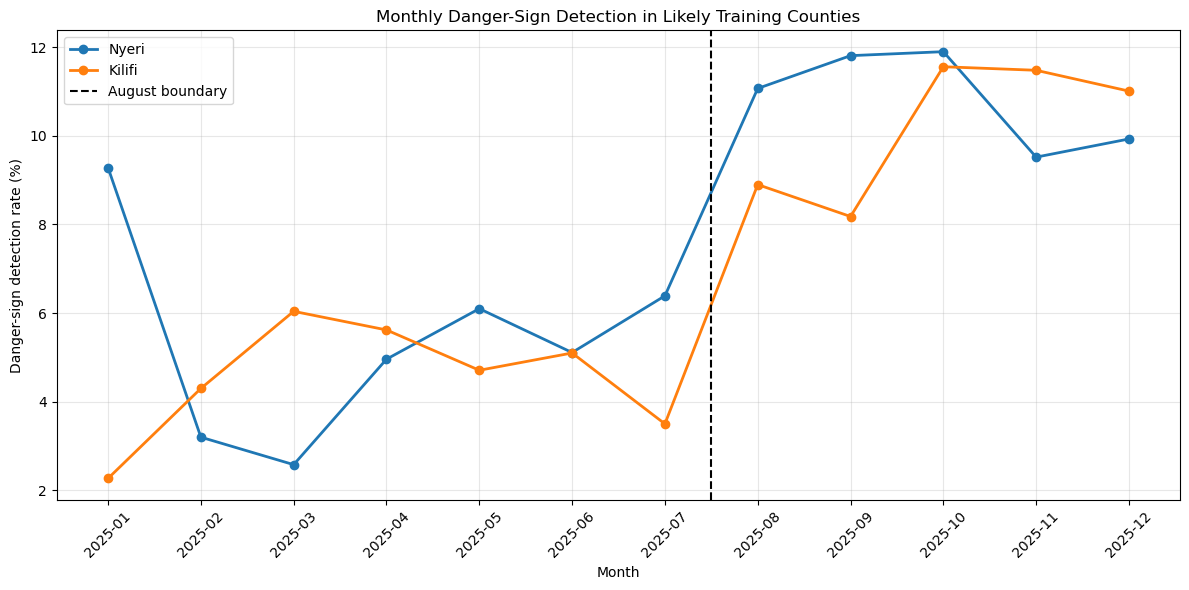

In [57]:
# PLOT DANGER-SIGN DETECTION OVER TIME
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for county in training_counties:
    
    county_data = training_county_monthly[
        training_county_monthly['county'] == county
    ].sort_values('month')
    
    plt.plot(
        county_data['month'].astype(str),
        county_data['detection_percent'],
        marker='o',
        linewidth=2,
        label=county
    )

# Mark the assumed training boundary
plt.axvline(
    x=6.5,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='August boundary'
)

plt.title(
    'Monthly Danger-Sign Detection in Likely Training Counties'
)

plt.xlabel('Month')
plt.ylabel('Danger-sign detection rate (%)')

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [58]:
# COMPARE LIKELY TRAINING COUNTIES WITH OTHER COUNTIES
# ============================================================

# Create a broader before-after summary
# for all counties, using counts rather than averaging percentages.

all_county_period_summary = (
    danger_sign_visits
    .groupby(
        ['county', 'period'],
        as_index=False
    )
    .agg(
        total_visits=('visit_id', 'count'),
        detected_danger_signs=(
            'danger_sign_detected',
            'sum'
        )
    )
)

all_county_period_summary['detection_rate'] = (
    all_county_period_summary['detected_danger_signs']
    /
    all_county_period_summary['total_visits']
)

all_county_period_summary['detection_percent'] = (
    all_county_period_summary['detection_rate'] * 100
).round(2)

all_county_period_summary['training_group'] = np.where(
    all_county_period_summary['county'].isin(
        training_counties
    ),
    'Likely trained',
    'Other counties'
)

display(
    all_county_period_summary.sort_values(
        ['training_group', 'county', 'period']
    )
)

,county,period,total_visits,detected_danger_signs,detection_rate,detection_percent,training_group
4,Kilifi,August onward,796,82,0.103015,10.30,Likely trained
5,Kilifi,Before August,999,47,0.047047,4.70,Likely trained
10,Nyeri,August onward,1136,124,0.109155,10.92,Likely trained
11,Nyeri,Before August,1447,76,0.052522,5.25,Likely trained
0,Bungoma,August onward,698,42,0.060172,6.02,Other counties
1,Bungoma,Before August,977,64,0.065507,6.55,Other counties
2,Kakamega,August onward,1345,74,0.055019,5.50,Other counties
3,Kakamega,Before August,1584,98,0.061869,6.19,Other counties
6,Kisumu,August onward,599,66,0.110184,11.02,Other counties
7,Kisumu,Before August,844,49,0.058057,5.81,Other counties


In [59]:
# GROUP-LEVEL BEFORE-AFTER COMPARISON
# ============================================================

training_group_summary = (
    all_county_period_summary
    .groupby(
        ['training_group', 'period'],
        as_index=False
    )
    .agg(
        total_visits=('total_visits', 'sum'),
        detected_danger_signs=(
            'detected_danger_signs',
            'sum'
        )
    )
)

training_group_summary['detection_rate'] = (
    training_group_summary['detected_danger_signs']
    /
    training_group_summary['total_visits']
)

training_group_summary['detection_percent'] = (
    training_group_summary['detection_rate'] * 100
).round(2)

display(training_group_summary)

,training_group,period,total_visits,detected_danger_signs,detection_rate,detection_percent
0,Likely trained,August onward,1932,206,0.106625,10.66
1,Likely trained,Before August,2446,123,0.050286,5.03
2,Other counties,August onward,2995,206,0.068781,6.88
3,Other counties,Before August,3878,231,0.059567,5.96


In [60]:
# CALCULATE MONTHLY MALARIA VISIT VOLUME
# ============================================================

# Use the malaria_visits table created in Task B

malaria_visits['month'] = (
    malaria_visits['visit_date']
    .dt.to_period('M')
)

malaria_monthly_volume = (
    malaria_visits
    .groupby('month', as_index=False)
    .agg(
        malaria_visits=('visit_id', 'count')
    )
)

malaria_monthly_volume['month_number'] = (
    malaria_monthly_volume['month']
    .dt.month
)

malaria_monthly_volume['month_name'] = (
    malaria_monthly_volume['month']
    .dt.strftime('%B')
)

display(malaria_monthly_volume)


,month,malaria_visits,month_number,month_name
0,2025-01,279,1,January
1,2025-02,290,2,February
2,2025-03,461,3,March
3,2025-04,699,4,April
4,2025-05,710,5,May
5,2025-06,442,6,June
6,2025-07,300,7,July
7,2025-08,268,8,August
8,2025-09,324,9,September
9,2025-10,591,10,October


In [61]:
# IDENTIFY MALARIA PEAK AND LOW MONTHS
# ============================================================

peak_month = malaria_monthly_volume.loc[
    malaria_monthly_volume['malaria_visits'].idxmax()
]

low_month = malaria_monthly_volume.loc[
    malaria_monthly_volume['malaria_visits'].idxmin()
]

print('Peak malaria visit month:')
print(
    peak_month['month_name'],
    '-',
    peak_month['malaria_visits'],
    'visits'
)

print('\nLowest malaria visit month:')
print(
    low_month['month_name'],
    '-',
    low_month['malaria_visits'],
    'visits'
)

print('\nAverage monthly malaria visits:')
print(
    round(
        malaria_monthly_volume['malaria_visits'].mean(),
        2
    )
)

print('\nStandard deviation of monthly malaria visits:')
print(
    round(
        malaria_monthly_volume['malaria_visits'].std(),
        2
    )
)

print('\nCoefficient of variation:')
print(
    round(
        malaria_monthly_volume['malaria_visits'].std()
        /
        malaria_monthly_volume['malaria_visits'].mean(),
        3
    )
)

Peak malaria visit month:
November - 712 visits

Lowest malaria visit month:
August - 268 visits

Average monthly malaria visits:
456.75

Standard deviation of monthly malaria visits:
177.39

Coefficient of variation:
0.388


In [62]:
# TEST WHETHER MONTHLY MALARIA VOLUME VARIES
# ============================================================

from scipy.stats import chisquare

# Test whether visits were evenly distributed across 12 months.
# Expected count assumes the same number of visits each month.

observed_counts = (
    malaria_monthly_volume['malaria_visits']
)

expected_count = (
    observed_counts.sum()
    /
    len(observed_counts)
)

expected_counts = [
    expected_count
] * len(observed_counts)

chi_square_statistic, chi_square_p_value = chisquare(
    f_obs=observed_counts,
    f_exp=expected_counts
)

print('Chi-square statistic:',
      round(chi_square_statistic, 2))

print('Chi-square p-value:',
      round(chi_square_p_value, 5))

if chi_square_p_value < 0.05:
    print(
        'Conclusion: monthly malaria visit volume is not evenly distributed.'
    )
else:
    print(
        'Conclusion: no statistically significant evidence of monthly variation.'
    )

Chi-square statistic: 757.81
Chi-square p-value: 0.0
Conclusion: monthly malaria visit volume is not evenly distributed.


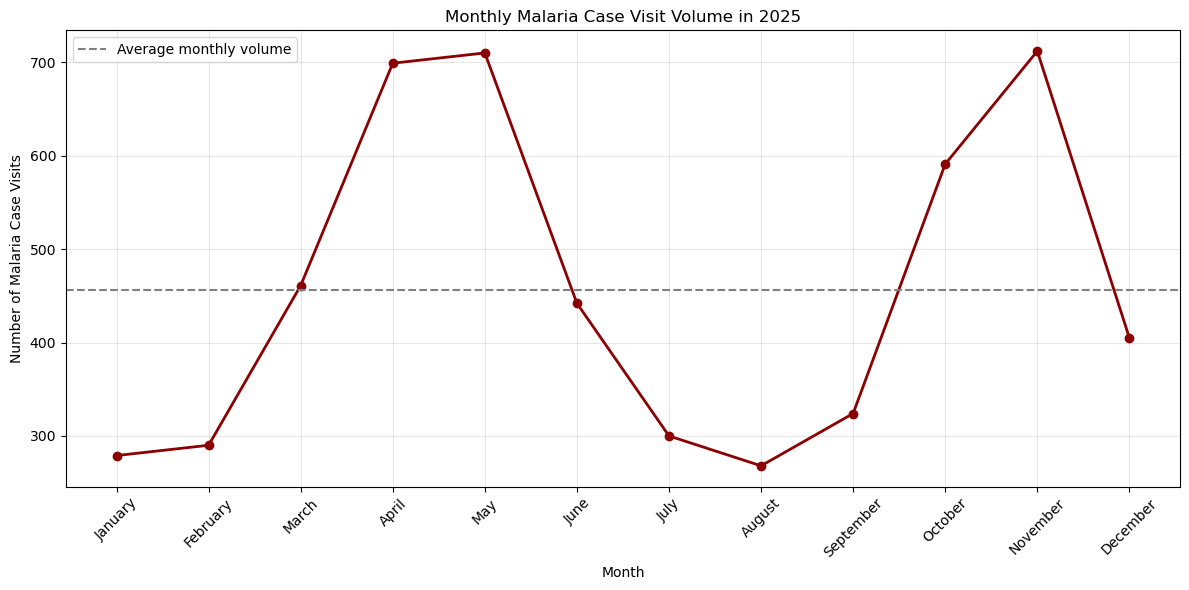

In [63]:
# PLOT MONTHLY MALARIA VISIT VOLUME
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    malaria_monthly_volume['month_name'],
    malaria_monthly_volume['malaria_visits'],
    marker='o',
    linewidth=2,
    color='darkred'
)

plt.axhline(
    malaria_monthly_volume['malaria_visits'].mean(),
    color='gray',
    linestyle='--',
    label='Average monthly volume'
)

plt.title('Monthly Malaria Case Visit Volume in 2025')
plt.xlabel('Month')
plt.ylabel('Number of Malaria Case Visits')

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [67]:
# SAVE TASK C RESULTS
# ============================================================

test_results.to_csv(
    'task_c_danger_sign_statistical_tests.csv',
    index=False
)

before_after_danger_sign.to_csv(
    'task_c_danger_sign_before_after.csv',
    index=False
)

training_county_monthly.to_csv(
    'task_c_training_county_monthly.csv',
    index=False
)

training_group_summary.to_csv(
    'task_c_training_group_summary.csv',
    index=False
)

malaria_monthly_volume.to_csv(
    'task_c_monthly_malaria_volume.csv',
    index=False
)

print('Task C results saved:')
print('- task_c_danger_sign_statistical_tests.csv')
print('- task_c_danger_sign_before_after.csv')
print('- task_c_training_county_monthly.csv')
print('- task_c_training_group_summary.csv')
print('- task_c_monthly_malaria_volume.csv')

Task C results saved:
- task_c_danger_sign_statistical_tests.csv
- task_c_danger_sign_before_after.csv
- task_c_training_county_monthly.csv
- task_c_training_group_summary.csv
- task_c_monthly_malaria_volume.csv


In [68]:
# FINAL TASK C CHECK
# ============================================================

print('--- Likely training counties ---')
print(training_counties)

print('\n--- Statistical test results ---')
display(
    test_results[
        [
            'county',
            'change_percentage_points',
            'p_value',
            'change_vs_monthly_variation',
            'likely_training_county'
        ]
    ]
)

print('\n--- Monthly malaria visit volume ---')
display(malaria_monthly_volume)

print('\n--- Peak malaria month ---')
print(
    peak_month['month_name'],
    peak_month['malaria_visits']
)

print('\n--- Lowest malaria month ---')
print(
    low_month['month_name'],
    low_month['malaria_visits']
)

--- Likely training counties ---
['Nyeri', 'Kilifi']

--- Statistical test results ---


,county,change_percentage_points,p_value,change_vs_monthly_variation,likely_training_county
5,Nyeri,5.67,0.0000,2.55,True
2,Kilifi,5.60,0.0000,4.33,True
3,Kisumu,5.21,0.0003,1.92,False
4,Machakos,2.57,0.1036,0.96,False
1,Kakamega,-0.69,0.4320,-0.49,False
0,Bungoma,-0.53,0.6584,-0.23,False



--- Monthly malaria visit volume ---


,month,malaria_visits,month_number,month_name
0,2025-01,279,1,January
1,2025-02,290,2,February
2,2025-03,461,3,March
3,2025-04,699,4,April
4,2025-05,710,5,May
5,2025-06,442,6,June
6,2025-07,300,7,July
7,2025-08,268,8,August
8,2025-09,324,9,September
9,2025-10,591,10,October



--- Peak malaria month ---
November 712

--- Lowest malaria month ---
August 268


In [69]:
# TASK D
# SET UP VISUALIZATION OUTPUTS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create a folder for charts and written outputs
task_d_output = Path('task_d_outputs')
task_d_output.mkdir(exist_ok=True)

# Professional chart style
sns.set_theme(
    style='whitegrid',
    context='notebook'
)

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

print('Task D setup completed.')

Task D setup completed.


In [70]:
# TASK D
# CHECK INPUT TABLES FOR VISUALIZATION
# ============================================================

print('Malaria table:')
print(malaria_by_chu.shape)

print('\nReferral completion by county:')
print(referral_completion_by_county.shape)

print('\nReferral completion by module:')
print(referral_completion_by_module.shape)

print('\nMonthly malaria volume:')
print(malaria_monthly_volume.shape)

print('\nDanger-sign before-after table:')
print(before_after_wide.shape)

Malaria table:
(48, 9)

Referral completion by county:
(6, 7)

Referral completion by module:
(4, 7)

Monthly malaria volume:
(12, 4)

Danger-sign before-after table:
(6, 8)


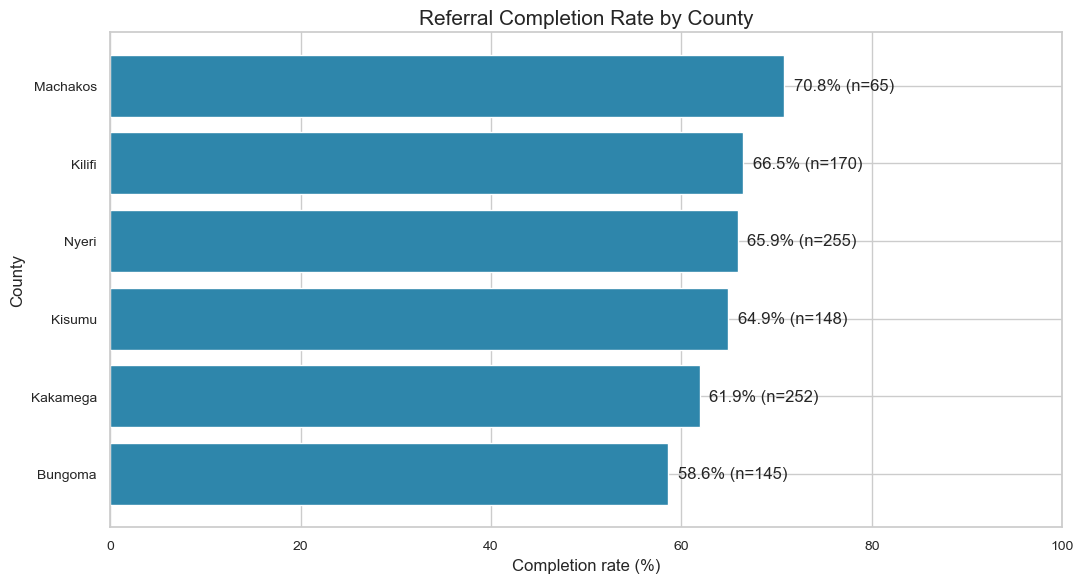

In [71]:
# TASK D
# CHART 1: REFERRAL COMPLETION BY COUNTY
# ============================================================

chart_referrals = referral_completion_by_county.copy()

chart_referrals = chart_referrals.sort_values(
    'completion_percent',
    ascending=True
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    chart_referrals['county'],
    chart_referrals['completion_percent'],
    color='#2E86AB'
)

plt.title(
    'Referral Completion Rate by County'
)

plt.xlabel('Completion rate (%)')
plt.ylabel('County')

plt.xlim(0, 100)

# Add percentage labels
for bar, percentage, total in zip(
    bars,
    chart_referrals['completion_percent'],
    chart_referrals['total_referrals']
):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{percentage:.1f}% (n={total})',
        va='center'
    )

plt.tight_layout()

plt.savefig(
    task_d_output / 'chart_1_referral_completion_by_county.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

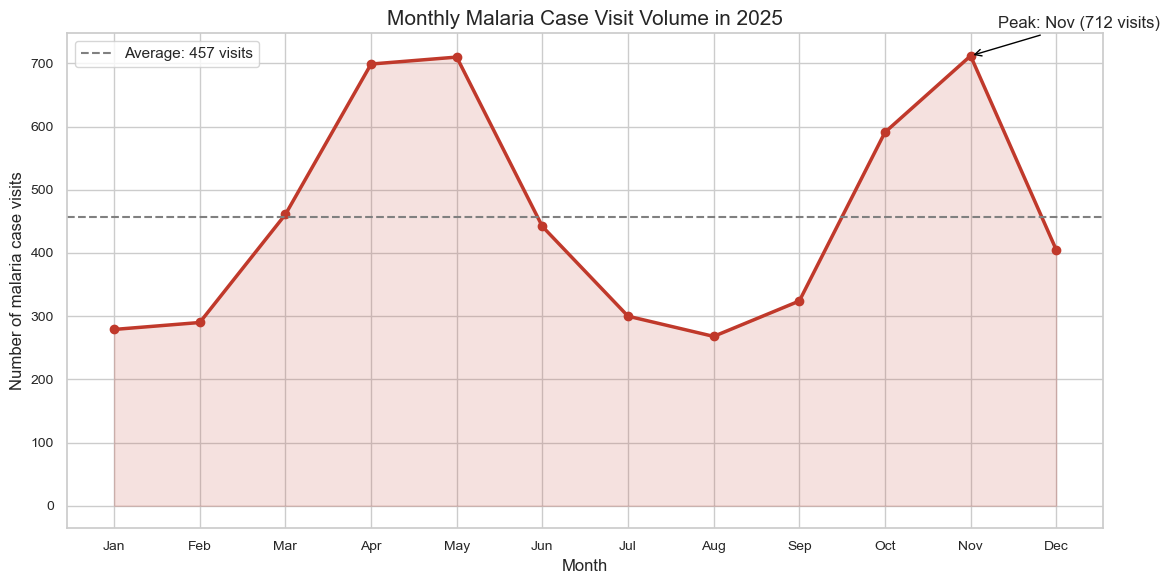

In [72]:
# TASK D
# CHART 2: MONTHLY MALARIA VISIT VOLUME
# ============================================================

chart_malaria = malaria_monthly_volume.copy()

# Create readable month labels
chart_malaria['month_label'] = (
    chart_malaria['month']
    .dt.strftime('%b')
)

average_malaria_volume = (
    chart_malaria['malaria_visits']
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    chart_malaria['month_label'],
    chart_malaria['malaria_visits'],
    marker='o',
    linewidth=2.5,
    color='#C0392B'
)

plt.fill_between(
    chart_malaria['month_label'],
    chart_malaria['malaria_visits'],
    alpha=0.15,
    color='#C0392B'
)

plt.axhline(
    average_malaria_volume,
    color='gray',
    linestyle='--',
    linewidth=1.5,
    label=f'Average: {average_malaria_volume:.0f} visits'
)

peak_row = chart_malaria.loc[
    chart_malaria['malaria_visits'].idxmax()
]

plt.annotate(
    f"Peak: {peak_row['month_label']} "
    f"({peak_row['malaria_visits']} visits)",
    xy=(
        peak_row['month_label'],
        peak_row['malaria_visits']
    ),
    xytext=(20, 20),
    textcoords='offset points',
    arrowprops=dict(
        arrowstyle='->',
        color='black'
    )
)

plt.title(
    'Monthly Malaria Case Visit Volume in 2025'
)

plt.xlabel('Month')
plt.ylabel('Number of malaria case visits')

plt.legend()
plt.tight_layout()

plt.savefig(
    task_d_output / 'chart_2_monthly_malaria_volume.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

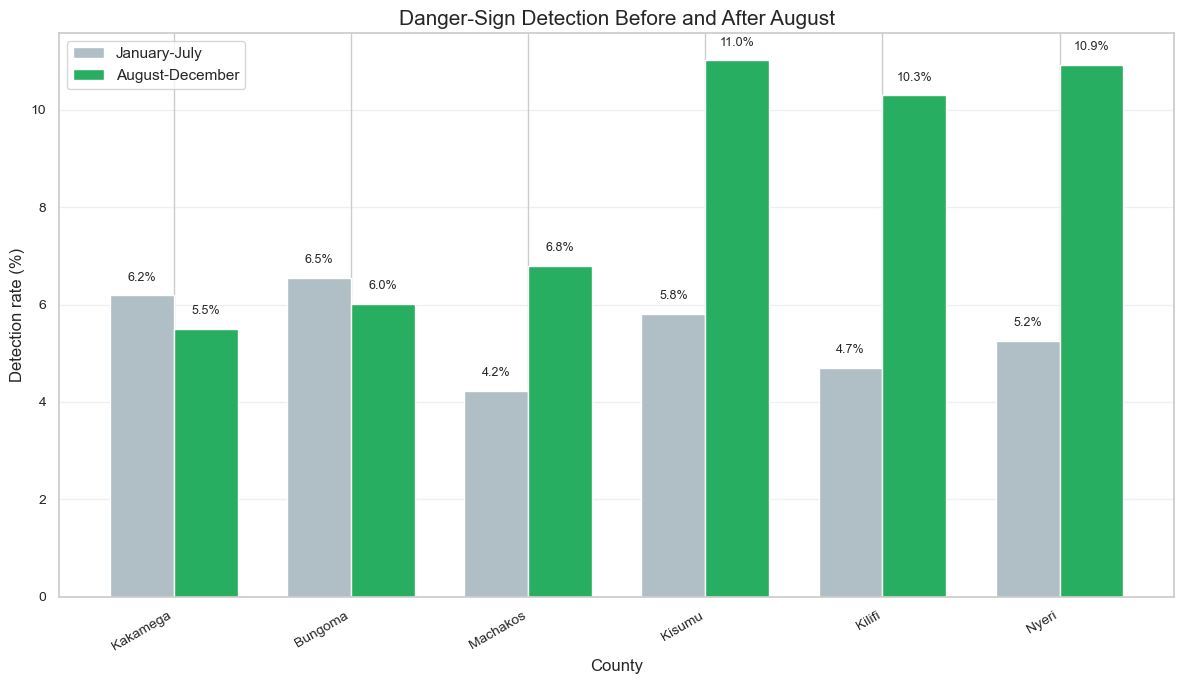

In [73]:
# CHART 3: DANGER-SIGN DETECTION BEFORE AND AFTER AUGUST
# ============================================================

chart_danger = before_after_wide.copy()

chart_danger = chart_danger.sort_values(
    'change_percentage_points',
    ascending=True
)

x = np.arange(len(chart_danger))
width = 0.36

before_values = chart_danger[
    'detection_percent_Before August'
]

after_values = chart_danger[
    'detection_percent_August onward'
]

plt.figure(figsize=(12, 7))

plt.bar(
    x - width / 2,
    before_values,
    width,
    label='January-July',
    color='#B0BEC5'
)

plt.bar(
    x + width / 2,
    after_values,
    width,
    label='August-December',
    color='#27AE60'
)

plt.xticks(
    x,
    chart_danger['county'],
    rotation=30,
    ha='right'
)

plt.title(
    'Danger-Sign Detection Before and After August'
)

plt.xlabel('County')
plt.ylabel('Detection rate (%)')

plt.legend()
plt.grid(axis='y', alpha=0.3)

# Add labels to the bars
for i, value in enumerate(before_values):
    plt.text(
        i - width / 2,
        value + 0.3,
        f'{value:.1f}%',
        ha='center',
        fontsize=9
    )

for i, value in enumerate(after_values):
    plt.text(
        i + width / 2,
        value + 0.3,
        f'{value:.1f}%',
        ha='center',
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    task_d_output / 'chart_3_danger_sign_before_after.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [74]:
# CREATE A MANAGEMENT SUMMARY TABLE
# ============================================================

# Overall malaria indicators
overall_malaria_visits = len(malaria_visits)

overall_rdt_done = malaria_visits[
    'rdt_done'
].sum()

overall_rdt_positive = malaria_visits[
    'rdt_positive'
].sum()

overall_act_positive = malaria_visits[
    'act_dispensed_flag'
].sum()

overall_rdt_positivity = (
    overall_rdt_positive
    /
    overall_rdt_done
    *
    100
)

overall_act_rate = (
    overall_act_positive
    /
    overall_rdt_positive
    *
    100
)

# Overall referral indicators
overall_referrals = len(referrals_b)

overall_completed_referrals = referrals_b[
    'completed_flag'
].sum()

overall_referral_completion = (
    overall_completed_referrals
    /
    overall_referrals
    *
    100
)

# Training counties
likely_training_counties_text = ', '.join(
    training_counties
)

# Peak malaria month
peak_malaria_month = (
    peak_month['month_name']
)

peak_malaria_visits = (
    peak_month['malaria_visits']
)

management_summary_table = pd.DataFrame({
    'indicator': [
        'Total malaria case visits',
        'RDT positivity rate',
        'ACT dispensing among positive cases',
        'Total referrals',
        'Overall referral completion rate',
        'Peak malaria visit month',
        'Likely refresher-training counties'
    ],
    'value': [
        f'{overall_malaria_visits:,}',
        f'{overall_rdt_positivity:.1f}%',
        f'{overall_act_rate:.1f}%',
        f'{overall_referrals:,}',
        f'{overall_referral_completion:.1f}%',
        f'{peak_malaria_month} ({peak_malaria_visits:,} visits)',
        likely_training_counties_text
    ]
})

display(management_summary_table)

,indicator,value
0,Total malaria case visits,"5,481"
1,RDT positivity rate,35.8%
2,ACT dispensing among positive cases,93.0%
3,Total referrals,"1,035"
4,Overall referral completion rate,64.2%
5,Peak malaria visit month,November (712 visits)
6,Likely refresher-training counties,"Nyeri, Kilifi"


In [75]:
# WRITE THE EXECUTIVE SUMMARY
# ============================================================

lowest_referral_county = referral_completion_by_county.loc[
    referral_completion_by_county['completion_percent'].idxmin()
]

highest_referral_county = referral_completion_by_county.loc[
    referral_completion_by_county['completion_percent'].idxmax()
]

lowest_referral_module = referral_completion_by_module.loc[
    referral_completion_by_module['completion_percent'].idxmin()
]

highest_referral_module = referral_completion_by_module.loc[
    referral_completion_by_module['completion_percent'].idxmax()
]

largest_detection_increase = test_results.loc[
    test_results['change_percentage_points'].idxmax()
]

summary_text = f"""
EXECUTIVE SUMMARY — COMMUNITY HEALTH WORKER PROGRAM

Program activity:
- The program recorded {overall_malaria_visits:,} Malaria_Case visits in 2025.
- RDT positivity was {overall_rdt_positivity:.1f}% among visits where an RDT was done.
- ACT dispensing among positive RDT cases was {overall_act_rate:.1f}%.

Referral performance:
- There were {overall_referrals:,} referrals overall.
- The overall referral completion rate was {overall_referral_completion:.1f}%.
- Referral completion was highest in {highest_referral_county['county']} 
  at {highest_referral_county['completion_percent']:.1f}%.
- Referral completion was lowest in {lowest_referral_county['county']} 
  at {lowest_referral_county['completion_percent']:.1f}%.
- Completion was highest for {highest_referral_module['module']} referrals 
  and lowest for {lowest_referral_module['module']} referrals.

Danger-sign detection:
- Danger-sign detection increased most in {largest_detection_increase['county']},
  with a change of {largest_detection_increase['change_percentage_points']:.2f}
  percentage points after August.
- Counties identified as likely receiving refresher training were:
  {likely_training_counties_text}.

Seasonality:
- Malaria visit volume peaked in {peak_malaria_month}, with
  {peak_malaria_visits:,} visits.
- This pattern may reflect seasonal malaria transmission, increased care-seeking,
  or changes in outreach and reporting intensity.

Management message:
The program is generating substantial community-level activity, but referral follow-up
and documentation remain important improvement areas. The strongest apparent improvement
in danger-sign detection occurred after August in the likely training counties.
"""

print(summary_text)

with open(
    task_d_output / 'executive_summary.txt',
    'w',
    encoding='utf-8'
) as file:
    file.write(summary_text)


EXECUTIVE SUMMARY — COMMUNITY HEALTH WORKER PROGRAM

Program activity:
- The program recorded 5,481 Malaria_Case visits in 2025.
- RDT positivity was 35.8% among visits where an RDT was done.
- ACT dispensing among positive RDT cases was 93.0%.

Referral performance:
- There were 1,035 referrals overall.
- The overall referral completion rate was 64.2%.
- Referral completion was highest in Machakos 
  at 70.8%.
- Referral completion was lowest in Bungoma 
  at 58.6%.
- Completion was highest for Malaria_Case referrals 
  and lowest for PNC referrals.

Danger-sign detection:
- Danger-sign detection increased most in Nyeri,
  with a change of 5.67
  percentage points after August.
- Counties identified as likely receiving refresher training were:
  Nyeri, Kilifi.

Seasonality:
- Malaria visit volume peaked in November, with
  712 visits.
- This pattern may reflect seasonal malaria transmission, increased care-seeking,
  or changes in outreach and reporting intensity.

Management message

In [76]:
# CREATE ACTIONABLE RECOMMENDATIONS
# ============================================================

recommendations = pd.DataFrame({
    'priority': [
        1,
        2,
        3,
        4,
        5
    ],
    
    'recommendation': [
        'Strengthen referral follow-up and outcome reporting, especially in Bungoma.',
        'Use the refresher-training approach from the likely trained counties in counties with weaker danger-sign detection.',
        'Investigate the 505 malaria visits without a recorded RDT result.',
        'Prepare for malaria workload increases around the peak months by reviewing supplies and CHV coverage.',
        'Review CHV workload allocation because visit volumes differ substantially across CHVs and CHUs.'
    ],
    
    'reason': [
        'Bungoma recorded the lowest referral completion rate and has many unknown outcomes.',
        'Nyeri, Kilifi, and Kisumu show the clearest post-August improvement in detection.',
        'Missing RDT results reduce confidence in the malaria positivity indicator.',
        'The monthly malaria pattern suggests that demand is not evenly distributed across the year.',
        'A small group of CHVs records very high visit volumes compared with others.'
    ],
    
    'suggested_action': [
        'Introduce referral registers, weekly follow-up reviews, and mandatory outcome updates.',
        'Document the training package and use targeted coaching in lower-performing counties.',
        'Make RDT result entry mandatory for malaria visits unless clinically not tested.',
        'Pre-position RDT kits, ACT supplies, and supervisory support before peak months.',
        'Compare workload, household assignment, geography, and reporting practices before taking performance action.'
    ]
})

display(recommendations)

recommendations.to_csv(
    task_d_output / 'recommendations.csv',
    index=False
)

,priority,recommendation,reason,suggested_action
0,1,Strengthen referral follow-up and outcome repo...,Bungoma recorded the lowest referral completio...,"Introduce referral registers, weekly follow-up..."
1,2,Use the refresher-training approach from the l...,"Nyeri, Kilifi, and Kisumu show the clearest po...",Document the training package and use targeted...
2,3,Investigate the 505 malaria visits without a r...,Missing RDT results reduce confidence in the m...,Make RDT result entry mandatory for malaria vi...
3,4,Prepare for malaria workload increases around ...,The monthly malaria pattern suggests that dema...,"Pre-position RDT kits, ACT supplies, and super..."
4,5,Review CHV workload allocation because visit v...,A small group of CHVs records very high visit ...,"Compare workload, household assignment, geogra..."


In [77]:
# DOCUMENT ASSUMPTIONS AND DATA-TEAM QUESTIONS
# ============================================================

assumptions_and_questions = """
ASSUMPTIONS AND QUESTIONS FOR DATA TEAM

1. The assessment year was treated as January 1, 2025 to December 31, 2025.

2. Unknown referral outcomes were included in the denominator but not counted
   as completed.

3. RDT positivity was calculated only among malaria visits with a recorded
   positive or negative RDT result.

4. ACT dispensing was calculated only among positive RDT cases.

5. August was used as the approximate training boundary because the data showed
   a sustained increase in danger-sign detection from August onward in some counties.
   The actual training dates should be confirmed.

6. Danger-sign detection was assessed across ANC, PNC, and Malaria_Case visits.

7. The malaria seasonality analysis is exploratory. Visit volume may reflect disease
   seasonality, care-seeking, CHV availability, outreach scheduling, or reporting intensity.

8. The CHU reference table contains duplicate logical CHU IDs after normalization.
   The data team should confirm the authoritative CHU record before production reporting.

9. The data team should confirm whether missing RDT results mean the test was not done
   or whether the result was simply not recorded.

10. The data team should confirm whether referral outcomes are expected to be updated
    by CHVs, facilities, supervisors, or another reporting system.
"""

print(assumptions_and_questions)

with open(
    task_d_output / 'assumptions_and_questions.txt',
    'w',
    encoding='utf-8'
) as file:
    file.write(assumptions_and_questions)



ASSUMPTIONS AND QUESTIONS FOR DATA TEAM

1. The assessment year was treated as January 1, 2025 to December 31, 2025.

2. Unknown referral outcomes were included in the denominator but not counted
   as completed.

3. RDT positivity was calculated only among malaria visits with a recorded
   positive or negative RDT result.

4. ACT dispensing was calculated only among positive RDT cases.

5. August was used as the approximate training boundary because the data showed
   a sustained increase in danger-sign detection from August onward in some counties.
   The actual training dates should be confirmed.

6. Danger-sign detection was assessed across ANC, PNC, and Malaria_Case visits.

7. The malaria seasonality analysis is exploratory. Visit volume may reflect disease
   seasonality, care-seeking, CHV availability, outreach scheduling, or reporting intensity.

8. The CHU reference table contains duplicate logical CHU IDs after normalization.
   The data team should confirm the authoritativ

In [78]:
# SAVE ALL TASK D TABLES IN ONE EXCEL WORKBOOK
# ============================================================

with pd.ExcelWriter(
    task_d_output / 'task_d_results.xlsx',
    engine='openpyxl'
) as writer:
    
    management_summary_table.to_excel(
        writer,
        sheet_name='Management_Summary',
        index=False
    )
    
    recommendations.to_excel(
        writer,
        sheet_name='Recommendations',
        index=False
    )
    
    referral_completion_by_county.to_excel(
        writer,
        sheet_name='Referrals_by_County',
        index=False
    )
    
    referral_completion_by_module.to_excel(
        writer,
        sheet_name='Referrals_by_Module',
        index=False
    )
    
    malaria_by_chu.to_excel(
        writer,
        sheet_name='Malaria_by_CHU',
        index=False
    )
    
    malaria_monthly_volume.to_excel(
        writer,
        sheet_name='Monthly_Malaria',
        index=False
    )
    
    test_results.to_excel(
        writer,
        sheet_name='Danger_Sign_Tests',
        index=False
    )

print('Saved:', task_d_output / 'task_d_results.xlsx')

Saved: task_d_outputs/task_d_results.xlsx


In [79]:
# FINAL TASK D OUTPUT CHECK
# ============================================================

print('Task D completed successfully.')

print('\nFiles created:')

for file in sorted(task_d_output.iterdir()):
    print('-', file.name)

Task D completed successfully.

Files created:
- assumptions_and_questions.txt
- chart_1_referral_completion_by_county.png
- chart_2_monthly_malaria_volume.png
- chart_3_danger_sign_before_after.png
- executive_summary.txt
- recommendations.csv
- task_d_results.xlsx


In [82]:
# TASK A — DATA QUALITY REPORT
# TASK B — ANALYSIS RESULTS USED
# TASK D — WRITTEN SUMMARY AND RECOMMENDATIONS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# CREATE OUTPUT FOLDER
# ------------------------------------------------------------

output_folder = Path('final_submission_outputs')
output_folder.mkdir(exist_ok=True)


# ============================================================
# TASK A — SAVE THE DATA QUALITY REPORT
# ============================================================

# The object quality_report was created during Task A.
# It contains the issue category, dataset, issue, affected records,
# detection method, recommended action, and reason.

quality_report.to_csv(
    output_folder / 'TASK_A_quality_report.csv',
    index=False
)

print('TASK A QUALITY REPORT SAVED:')
print(output_folder / 'TASK_A_quality_report.csv')


# ============================================================
# TASK B — COLLECT KEY ANALYSIS RESULTS
# ============================================================

# Total visits and referrals
total_cleaned_visits = len(visits_clean_2025)
total_cleaned_referrals = len(referrals_clean_2025)

# Malaria results
total_malaria_visits = len(malaria_visits)

total_rdt_done = int(
    malaria_visits['rdt_done'].sum()
)

total_rdt_positive = int(
    malaria_visits['rdt_positive'].sum()
)

total_act_dispensed = int(
    malaria_visits['act_dispensed_flag'].sum()
)

rdt_positivity_rate = (
    total_rdt_positive
    /
    total_rdt_done
    *
    100
)

act_dispensing_rate = (
    total_act_dispensed
    /
    total_rdt_positive
    *
    100
)

# Referral results
total_referrals = len(referrals_b)

completed_referrals = int(
    referrals_b['completed_flag'].sum()
)

not_completed_referrals = int(
    (referrals_b['outcome'] == 'not_completed').sum()
)

unknown_referrals = int(
    (referrals_b['outcome'] == 'unknown').sum()
)

referral_completion_rate = (
    completed_referrals
    /
    total_referrals
    *
    100
)

# Highest and lowest referral completion counties
highest_referral_county = (
    referral_completion_by_county
    .sort_values(
        'completion_percent',
        ascending=False
    )
    .iloc[0]
)

lowest_referral_county = (
    referral_completion_by_county
    .sort_values(
        'completion_percent',
        ascending=True
    )
    .iloc[0]
)

# Highest and lowest referral completion modules
highest_referral_module = (
    referral_completion_by_module
    .sort_values(
        'completion_percent',
        ascending=False
    )
    .iloc[0]
)

lowest_referral_module = (
    referral_completion_by_module
    .sort_values(
        'completion_percent',
        ascending=True
    )
    .iloc[0]
)

# Top five CHVs
top_chv_names = top_5_chvs['chw_name'].tolist()

# Likely training counties
if 'training_counties' in globals():
    likely_training_counties = training_counties
else:
    likely_training_counties = []

if len(likely_training_counties) == 0:
    training_counties_text = (
        'No counties met the strict statistical rule used.'
    )
else:
    training_counties_text = ', '.join(
        likely_training_counties
    )

# Peak malaria month
peak_malaria_row = (
    malaria_monthly_volume
    .sort_values(
        'malaria_visits',
        ascending=False
    )
    .iloc[0]
)

peak_malaria_month = peak_malaria_row['month_name']
peak_malaria_visits = int(
    peak_malaria_row['malaria_visits']
)

# Largest danger-sign increase
largest_detection_increase = (
    test_results
    .sort_values(
        'change_percentage_points',
        ascending=False
    )
    .iloc[0]
)


# ============================================================
# TASK D — WRITTEN SUMMARY
# ============================================================

written_summary = f"""
TASK A — DATA QUALITY SUMMARY

I began the assessment by checking the quality of the six program tables
before calculating any performance indicators. I preserved the raw data
and worked with copies of the visits and referrals tables.

The main quality checks covered duplicate records, missing required fields,
invalid dates, inconsistent categorical coding, invalid module-specific
values, cross-field inconsistencies, referential integrity, and duplicate
CHU reference IDs.

The quality report documented the following main issues:

- 103 visits had missing or non-2025 visit dates.
- 6 referrals had completion dates earlier than their referral dates.
- 563 visit records had inconsistent module labels.
- 64 visits had implausible MUAC values.
- 80 visits referenced client IDs that were not found in clients.csv.
- Duplicate logical CHU IDs were identified after trimming spaces and
  standardizing ID capitalization.

I normalized identifiers by removing extra spaces and converting them to
uppercase. I standardized module names and referral outcomes. Exact
duplicates were removed. Impossible numeric values were set to missing
rather than guessed or imputed. Records outside the 2025 assessment period
were excluded from the main 2025 analytical datasets but retained as
exceptions. Unknown referral outcomes were not counted as completed.

The cleaned datasets used for later analysis contained:

- {total_cleaned_visits:,} cleaned 2025 visits.
- {total_cleaned_referrals:,} cleaned 2025 referrals.


TASK B — KEY ANALYSIS RESULTS

The cleaned data contained {total_malaria_visits:,} Malaria_Case visits.

RDT positivity was calculated only among visits where an RDT was actually
recorded as positive or negative. There were {total_rdt_done:,} visits
with an RDT result and {total_rdt_positive:,} positive RDT results.

The overall RDT positivity rate was:

{total_rdt_positive:,} / {total_rdt_done:,}
= {rdt_positivity_rate:.1f}%

ACT dispensing was calculated among RDT-positive cases only. There were
{total_act_dispensed:,} positive cases with ACT dispensed out of
{total_rdt_positive:,} positive cases.

The ACT dispensing rate among positive RDT cases was:

{total_act_dispensed:,} / {total_rdt_positive:,}
= {act_dispensing_rate:.1f}%

There were {total_referrals:,} referrals in total:

- {completed_referrals:,} completed referrals.
- {not_completed_referrals:,} not-completed referrals.
- {unknown_referrals:,} referrals with unknown outcomes.

Referral completion was defined as completed referrals divided by all
referrals. Unknown outcomes remained in the denominator but were not counted
as completed.

The overall referral completion rate was:

{completed_referrals:,} / {total_referrals:,}
= {referral_completion_rate:.1f}%

The county with the highest referral completion rate was
{highest_referral_county['county']} at
{highest_referral_county['completion_percent']:.1f}%.

The county with the lowest referral completion rate was
{lowest_referral_county['county']} at
{lowest_referral_county['completion_percent']:.1f}%.

By module, referral completion was highest for
{highest_referral_module['module']} at
{highest_referral_module['completion_percent']:.1f}% and lowest for
{lowest_referral_module['module']} at
{lowest_referral_module['completion_percent']:.1f}%.

The five CHVs with the highest total visit volume were:

{', '.join(top_chv_names)}

Their average visits per active month were calculated using the number of
distinct months in which each CHV recorded at least one visit. I did not
divide every CHV's annual visits by 12 because that would unfairly penalize
CHVs who were active for fewer months.


TASK C — STATISTICAL REASONING

Because the exact refresher-training dates were not included in the data,
August was used as an analytical breakpoint. Danger-sign detection was
compared between January-July and August-December.

The largest increase in danger-sign detection occurred in
{largest_detection_increase['county']}, with a change of
{largest_detection_increase['change_percentage_points']:.2f}
percentage points.

The analysis also compared the before-and-after change with normal
month-to-month variation during the pre-period. This helps distinguish a
possible intervention signal from ordinary random fluctuation.

The likely training counties identified under the statistical rule were:

{training_counties_text}

This result should be interpreted as evidence of a possible training effect,
not proof of causation. The exact training dates, training attendance, and
supervision records should be confirmed with the program team.

Malaria visit volume peaked in {peak_malaria_month}, with
{peak_malaria_visits:,} visits.

Possible explanations for monthly variation include seasonal malaria
transmission, rainfall, care-seeking behavior, outreach scheduling,
availability of CHVs, supply availability, and differences in reporting.


TASK D — MANAGEMENT SUMMARY

The program recorded substantial community-level activity during 2025.
Malaria visits were high, RDT positivity was measurable among tested
visits, and ACT dispensing among positive cases was generally strong.

However, the analysis also identified important documentation gaps. Missing
RDT results limit confidence in the malaria indicators, while unknown
referral outcomes reduce visibility of what happened after a referral.

Several counties showed improved danger-sign detection after the August
breakpoint, but this should be validated against official training dates
and other operational information.

Referral performance varied across counties and modules. These differences
should be interpreted together with referral volume and the number of
unknown outcomes rather than percentages alone.

The top CHVs recorded substantially higher visit volumes than many others.
This may indicate strong productivity, but it may also reflect differences
in assigned households, population size, geography, or workload allocation.


TASK D — ACTIONABLE RECOMMENDATIONS

1. Strengthen referral follow-up and outcome documentation, especially in
   counties with lower completion rates or many unknown outcomes.

2. Confirm the exact refresher-training dates and compare official trained
   counties with counties that did not receive the training.

3. Investigate malaria visits without recorded RDT results and clarify
   whether the missing result means the test was not done or was not recorded.

4. Prepare RDT kits, ACT supplies, supervision, and CHV coverage before
   months with higher malaria visit volume.

5. Review CHV workload allocation before using total visit volume as a
   performance judgment. Consider household population, geography, and the
   number of assigned households.


TASK D — DATA-TEAM HANDOFF QUESTIONS

- What were the exact dates of the refresher training?
- Which counties and CHVs attended the training?
- Does a missing RDT result mean that testing was not done or that the
  result was not recorded?
- Who is responsible for updating referral outcomes?
- How should referral records with a completion date but no outcome be treated?
- Which CHU record is authoritative where duplicate normalized CHU IDs exist?
- Are all CHVs assigned similar household populations and geographic areas?
"""

print(written_summary)


# ============================================================
# SAVE TASK D SUMMARY
# ============================================================

with open(
    output_folder / 'TASK_D_written_summary.txt',
    'w',
    encoding='utf-8'
) as file:
    file.write(written_summary)

print('TASK D WRITTEN SUMMARY SAVED:')
print(output_folder / 'TASK_D_written_summary.txt')


# ============================================================
# SAVE RECOMMENDATIONS AS CSV
# ============================================================

recommendations = pd.DataFrame({
    'priority': [1, 2, 3, 4, 5],
    'recommendation': [
        'Strengthen referral follow-up and outcome documentation.',
        'Confirm training dates and target supervision appropriately.',
        'Investigate missing malaria RDT results.',
        'Prepare supplies and staffing before peak malaria months.',
        'Review CHV workload differences before judging performance.'
    ]
})

recommendations.to_csv(
    output_folder / 'TASK_D_recommendations.csv',
    index=False
)

print('TASK D RECOMMENDATIONS SAVED:')
print(output_folder / 'TASK_D_recommendations.csv')


# ============================================================
# SAVE ONE COMBINED TEXT REPORT
# ============================================================

combined_report = (
    written_summary
)

with open(
    output_folder / 'TASK_A_TASK_B_TASK_D_report.txt',
    'w',
    encoding='utf-8'
) as file:
    file.write(combined_report)

print('COMBINED REPORT SAVED:')
print(output_folder / 'TASK_A_TASK_B_TASK_D_report.txt')


# ============================================================
# FINAL FILE LIST
# ============================================================

print('\nFINAL OUTPUT FILES:')

for file in sorted(output_folder.iterdir()):
    print('-', file.name)

TASK A QUALITY REPORT SAVED:
final_submission_outputs/TASK_A_quality_report.csv

TASK A — DATA QUALITY SUMMARY

I began the assessment by checking the quality of the six program tables
before calculating any performance indicators. I preserved the raw data
and worked with copies of the visits and referrals tables.

The main quality checks covered duplicate records, missing required fields,
invalid dates, inconsistent categorical coding, invalid module-specific
values, cross-field inconsistencies, referential integrity, and duplicate
CHU reference IDs.

The quality report documented the following main issues:

- 103 visits had missing or non-2025 visit dates.
- 6 referrals had completion dates earlier than their referral dates.
- 563 visit records had inconsistent module labels.
- 64 visits had implausible MUAC values.
- 80 visits referenced client IDs that were not found in clients.csv.
- Duplicate logical CHU IDs were identified after trimming spaces and
  standardizing ID capitalizat

Report created successfully: task_a_and_task_d_submission_report.docx


In [83]:
import pandas as pd
import numpy as np
import plotly.express as px
import ipywidgets as widgets

from IPython.display import display, clear_output

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

In [84]:
# --- Load files from the same folder as the notebook ---

from pathlib import Path

DATA_DIR = Path('.')

def find_file(file_name):
    matches = sorted(DATA_DIR.glob(f'*{file_name}'))
    
    if len(matches) == 0:
        raise FileNotFoundError(
            f'Could not find {file_name}'
        )
    
    return matches[0]

chus = pd.read_csv(find_file('chus.csv'))
chws = pd.read_csv(find_file('chws.csv'))
households = pd.read_csv(find_file('households.csv'))
clients = pd.read_csv(find_file('clients.csv'))
visits = pd.read_csv(find_file('visits.csv'))
referrals = pd.read_csv(find_file('referrals.csv'))

print('Files loaded successfully.')

for name, df in [
    ('chus', chus),
    ('chws', chws),
    ('households', households),
    ('clients', clients),
    ('visits', visits),
    ('referrals', referrals)
]:
    print(f'{name}: {len(df):,} rows')

Files loaded successfully.
chus: 20 rows
chws: 76 rows
households: 2,500 rows
clients: 10,104 rows
visits: 26,771 rows
referrals: 1,046 rows


In [85]:
# --- Helper functions ---

def normalize_id(series):
    return (
        series.astype('string')
        .str.strip()
        .str.upper()
    )

def normalize_text(series):
    return (
        series.astype('string')
        .str.strip()
        .str.lower()
    )


# --- Normalize identifiers ---

chus['chu_id_clean'] = normalize_id(chus['chu_id'])

chws['chw_id_clean'] = normalize_id(chws['chw_id'])
chws['chu_id_clean'] = normalize_id(chws['chu_id'])

clients['client_id_clean'] = normalize_id(
    clients['client_id']
)

visits['visit_id_clean'] = normalize_id(
    visits['visit_id']
)

visits['client_id_clean'] = normalize_id(
    visits['client_id']
)

visits['chu_id_clean'] = normalize_id(
    visits['chu_id']
)

visits['chw_id_clean'] = normalize_id(
    visits['chw_id']
)

referrals['referral_id_clean'] = normalize_id(
    referrals['referral_id']
)

referrals['visit_id_clean'] = normalize_id(
    referrals['visit_id']
)


# --- Convert dates ---

visits['visit_date'] = pd.to_datetime(
    visits['visit_date'],
    errors='coerce'
)

referrals['referral_date'] = pd.to_datetime(
    referrals['referral_date'],
    errors='coerce'
)


# --- Standardize modules ---

module_map = {
    'anc': 'ANC',
    'pnc': 'PNC',
    'immunization': 'Immunization',
    'immunisation': 'Immunization',
    'malnutrition_screening': 'Malnutrition_Screening',
    'malnutrition screening': 'Malnutrition_Screening',
    'malaria_case': 'Malaria_Case',
    'malaria case': 'Malaria_Case'
}

visits['module_clean'] = (
    normalize_text(visits['module'])
    .map(module_map)
)

referrals['module_clean'] = (
    normalize_text(referrals['module'])
    .map(module_map)
)


# --- Keep only 2025 visits ---

visits_2025 = visits[
    visits['visit_date'].between(
        '2025-01-01',
        '2025-12-31'
    )
    &
    visits['module_clean'].notna()
].copy()


# --- Keep only 2025 referrals ---

referrals_2025 = referrals[
    referrals['referral_date'].between(
        '2025-01-01',
        '2025-12-31'
    )
    &
    referrals['module_clean'].notna()
].copy()


# --- Malaria indicators ---

visits_2025['rdt_result_clean'] = normalize_text(
    visits_2025['rdt_result']
)

visits_2025['act_dispensed_clean'] = normalize_text(
    visits_2025['act_dispensed']
)

malaria = visits_2025[
    visits_2025['module_clean'] == 'Malaria_Case'
].copy()

malaria['rdt_done'] = malaria[
    'rdt_result_clean'
].isin([
    'positive',
    'negative'
])

malaria['rdt_positive'] = (
    malaria['rdt_result_clean'] == 'positive'
)

malaria['act_dispensed_flag'] = malaria[
    'act_dispensed_clean'
].isin([
    'true',
    'yes',
    '1'
])


# --- Referral indicators ---

referrals_2025['outcome_clean'] = (
    normalize_text(referrals_2025['outcome'])
    .map({
        'completed': 'completed',
        'yes': 'completed',
        '1': 'completed',
        'not completed': 'not_completed',
        'not_completed': 'not_completed',
        'no': 'not_completed',
        '0': 'not_completed',
        'unknown': 'unknown'
    })
    .fillna('unknown')
)

referrals_2025['completed_flag'] = (
    referrals_2025['outcome_clean'] == 'completed'
)

print('Cleaned analysis fields created.')
print('2025 visits:', len(visits_2025))
print('2025 referrals:', len(referrals_2025))
print('Malaria visits:', len(malaria))

Cleaned analysis fields created.
2025 visits: 26617
2025 referrals: 1046
Malaria visits: 5481


In [88]:
def create_dashboard(
    selected_counties,
    selected_modules
):
    
    filtered_visits = visits_2025[
        visits_2025['county'].isin(
            selected_counties
        )
        &
        visits_2025['module_clean'].isin(
            selected_modules
        )
    ].copy()
    
    filtered_referrals = referrals_2025[
        referrals_2025['county'].isin(
            selected_counties
        )
        &
        referrals_2025['module_clean'].isin(
            selected_modules
        )
    ].copy()
    
    filtered_malaria = filtered_visits[
        filtered_visits['module_clean']
        == 'Malaria_Case'
    ].copy()
    
    # --- KPI calculations ---
    
    total_visits = len(filtered_visits)
    total_referrals = len(filtered_referrals)
    total_malaria = len(filtered_malaria)
    
    rdt_done = int(
        filtered_malaria['rdt_done'].sum()
    )
    
    rdt_positive = int(
        filtered_malaria['rdt_positive'].sum()
    )
    
    act_dispensed = int(
        filtered_malaria['act_dispensed_flag'].sum()
    )
    
    completed_referrals = int(
        filtered_referrals['completed_flag'].sum()
    )
    
    rdt_rate = (
        100 * rdt_positive / rdt_done
        if rdt_done > 0 else 0
    )
    
    act_rate = (
        100 * act_dispensed / rdt_positive
        if rdt_positive > 0 else 0
    )
    
    referral_rate = (
        100 * completed_referrals
        / total_referrals
        if total_referrals > 0 else 0
    )
    
    # --- Display KPI table ---
    
    kpis = pd.DataFrame({
        'INDICATOR': [
            'TOTAL VISITS',
            'TOTAL REFERRALS',
            'MALARIA VISITS',
            'RDT POSITIVITY',
            'ACT AMONG POSITIVE CASES',
            'REFERRAL COMPLETION'
        ],
        'VALUE': [
            f'{total_visits:,}',
            f'{total_referrals:,}',
            f'{total_malaria:,}',
            f'{rdt_rate:.1f}%',
            f'{act_rate:.1f}%',
            f'{referral_rate:.1f}%'
        ]
    })
    
    display(kpis)
    
    # --- Chart 1: Visits by module ---
    
    module_counts = (
        filtered_visits[
            'module_clean'
        ]
        .value_counts()
        .reset_index()
    )
    
    module_counts.columns = [
        'module',
        'visit_count'
    ]
    
    fig1 = px.bar(
        module_counts,
        x='module',
        y='visit_count',
        color='module',
        title='VISITS BY PROGRAM MODULE'
    )
    
    fig1.show()
    
    # --- Chart 2: Referral completion by county ---
    
    referral_county = (
        filtered_referrals
        .groupby('county', as_index=False)
        .agg(
            total_referrals=(
                'referral_id',
                'count'
            ),
            completed_referrals=(
                'completed_flag',
                'sum'
            )
        )
    )
    
    referral_county[
        'completion_percent'
    ] = (
        100
        * referral_county['completed_referrals']
        / referral_county['total_referrals']
    ).round(1)
    
    fig2 = px.bar(
        referral_county.sort_values(
            'completion_percent'
        ),
        x='county',
        y='completion_percent',
        color='county',
        text='completion_percent',
        title='REFERRAL COMPLETION BY COUNTY'
    )
    
    fig2.update_traces(
        texttemplate='%{text:.1f}%',
        textposition='outside'
    )
    
    fig2.update_yaxes(range=[0, 100])
    fig2.show()
    
    # --- Chart 3: Monthly malaria volume ---
    
    filtered_malaria['month'] = (
        filtered_malaria['visit_date']
        .dt.to_period('M')
        .astype(str)
    )
    
    monthly_malaria = (
        filtered_malaria
        .groupby('month', as_index=False)
        .agg(
            malaria_visits=(
                'visit_id',
                'count'
            )
        )
    )
    
    fig3 = px.line(
        monthly_malaria,
        x='month',
        y='malaria_visits',
        markers=True,
        title='MONTHLY MALARIA CASE VISITS'
    )
    
    fig3.show()
    
    return (
        filtered_visits,
        filtered_referrals,
        referral_county,
        monthly_malaria
    )

In [89]:
county_options = sorted(
    visits_2025['county']
    .dropna()
    .unique()
    .tolist()
)

module_options = sorted(
    visits_2025['module_clean']
    .dropna()
    .unique()
    .tolist()
)

county_widget = widgets.SelectMultiple(
    options=county_options,
    value=tuple(county_options),
    description='COUNTY:',
    rows=6,
    layout=widgets.Layout(width='350px')
)

module_widget = widgets.SelectMultiple(
    options=module_options,
    value=tuple(module_options),
    description='MODULE:',
    rows=6,
    layout=widgets.Layout(width='350px')
)

run_button = widgets.Button(
    description='RUN DASHBOARD',
    button_style='primary'
)

output = widgets.Output()


def run_dashboard(button):
    with output:
        clear_output(wait=True)
        
        if len(county_widget.value) == 0:
            print('Please select at least one county.')
            return
        
        if len(module_widget.value) == 0:
            print('Please select at least one module.')
            return
        
        print('COMMUNITY HEALTH WORKER PROGRAM DASHBOARD')
        print('=' * 60)
        
        create_dashboard(
            list(county_widget.value),
            list(module_widget.value)
        )


run_button.on_click(run_dashboard)

display(
    widgets.HBox([
        county_widget,
        module_widget
    ])
)

display(run_button)
display(output)

Button(button_style='primary', description='RUN DASHBOARD', style=ButtonStyle())

Output()